# Metro Interstate Traffic Volume — Five-Model Forecasting Project
**Time Series Group Project · Group 5**

Hourly traffic on Interstate 94 (westbound) between Minneapolis and St Paul, Oct 2012 – Sep 2018
([UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume)).
This notebook implements the full plan from our proposal deck: **Part A** (data understanding and cleaning)
and **Part B** (five models evaluated under one common protocol).

| # | Family | Model | Task / horizon | Framework |
|---|--------|-------|----------------|-----------|
| 1 | Regression | LightGBM (+ Ridge baseline) | next hour (and a day-ahead variant) | LightGBM, scikit-learn |
| 2 | Clustering | K-Means on 24-hour daily profiles | group days by shape (not a forecast) | scikit-learn |
| 3 | Statistical | SARIMAX, s = 24 (+ Holt-Winters baseline) | 24 h ahead | statsmodels |
| 4 | Deep learning | LSTM (+ GRU alternative) | 24 h ahead, direct multi-step | **TensorFlow / Keras** |
| 5 | Transformer | PatchTST | 24 h ahead, direct multi-step | **TensorFlow / Keras** |

## Notebook map
1. Setup and configuration
2. Load data and audit it against the plan
3. Clean and resample to a regular hourly grid
4. Exploratory analysis
5. Evaluation protocol (chronological split, metrics, baselines)
6. Model 1 — LightGBM
7. Model 2 — K-Means
8. Model 3 — SARIMAX
9. Shared pipeline for the neural models
10. Model 4 — LSTM / GRU
11. Model 5 — PatchTST
12. Final comparison, takeaways and limitations

**How to run:** put `Metro_Interstate_Traffic_Volume.csv` next to the notebook (or edit `Config.data_path`) and run
top to bottom. Set `fast_dev_run=True` in `Config` for a quick smoke test (a few minutes instead of a full run).
All randomness is seeded, but multi-threaded CPU training can still differ slightly between runs.

## 1. Setup and configuration
Every tunable number lives in one frozen `Config` object, so nothing is hidden inside functions and a
change in one place is visible everywhere.

In [ ]:
# Uncomment if running on a fresh machine / Colab:
!pip install -q tensorflow lightgbm statsmodels scikit-learn pandas matplotlib

In [ ]:
import os
import warnings
from dataclasses import dataclass
from itertools import product
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge
from sklearn.metrics import adjusted_rand_score, silhouette_score
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import acf, adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from tensorflow import keras

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # keep TensorFlow's C++ logging quiet
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")
warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

I0000 00:00:1794194617.423720     717 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794194617.424752     717 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794194617.483230     717 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794194622.640659     717 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794194622.641022     717 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [ ]:
@dataclass(frozen=True)
class Config:
    """All tunable settings for the project in one place."""

    # --- data -------------------------------------------------------------------------------
    data_path: str = "Metro_Interstate_Traffic_Volume.csv"
    output_dir: str = "outputs"
    seed: int = 42
    fast_dev_run: bool = False          # True = tiny training budgets, for smoke-testing only

    # --- cleaning (Part A of the plan) ------------------------------------------------------
    max_interp_gap_hours: int = 3       # interpolate gaps up to this long; never impute longer ones
    rain_outlier_mm: float = 1000.0     # rain_1h above this is a sensor error (one 9,831 mm row)

    # --- chronological split ----------------------------------------------------------------
    train_frac: float = 0.70
    val_frac: float = 0.15              # test = the remaining 15 %

    # --- forecasting setup ------------------------------------------------------------------
    season_length: int = 24             # daily seasonality
    input_len: int = 168                # one week of history for the neural models
    horizon: int = 24                   # multi-step horizon for SARIMAX / LSTM / PatchTST

    # --- Model 1: LightGBM ------------------------------------------------------------------
    lag_hours: tuple = (1, 2, 3, 24, 168)
    rolling_window: int = 24

    # --- Model 2: K-Means -------------------------------------------------------------------
    n_clusters: int = 3                 # chosen from the elbow / silhouette plots in section 7
    cluster_scaling: str = "global"     # "global" (keeps daily shape) or "per_hour" (z-score each hour)

    # --- Model 3: SARIMAX -------------------------------------------------------------------
    sarimax_origin_step: int = 6        # forecast origins every N hours across the test stretch
    weekend_harmonics: int = 5          # Fourier pairs describing the weekend's daily shape

    # --- Models 4 & 5: neural training ------------------------------------------------------
    batch_size: int = 128
    max_epochs: int = 40
    patience: int = 6
    train_stride: int = 2               # use every k-th training window (neighbours are near-duplicates)
    run_gru: bool = True

    # PatchTST
    patch_len: int = 16
    patch_stride: int = 8
    d_model: int = 32                   # small on purpose: ~12k training windows, CPU-friendly
    n_heads: int = 4
    ff_dim: int = 64
    n_layers: int = 2
    dropout: float = 0.2

    @property
    def epochs(self) -> int:
        return 2 if self.fast_dev_run else self.max_epochs


cfg = Config()
keras.utils.set_random_seed(cfg.seed)          # seeds python, numpy and tensorflow together
Path(cfg.output_dir).mkdir(exist_ok=True)
print(f"TensorFlow {tf.__version__} | LightGBM {lgb.__version__} | pandas {pd.__version__}")
print("GPU devices:", tf.config.list_physical_devices("GPU") or "none (CPU run)")

TensorFlow 2.21.0 | LightGBM 4.7.0 | pandas 3.0.5
GPU devices: none (CPU run)


E0000 00:00:1794194623.301898     717 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Load data and audit it against the plan
Before touching anything, we reproduce the data-quality numbers from the deck. If a number does not match, we
want to know *now*, not after three models are trained on the wrong data.

In [ ]:
def load_raw(path: str) -> pd.DataFrame:
    """Read the UCI csv. The literal string 'None' in `holiday` means 'not a holiday', so we make it a real NaN."""
    raw = pd.read_csv(path, parse_dates=["date_time"])
    raw["holiday"] = raw["holiday"].where(raw["holiday"] != "None")
    return raw


raw = load_raw(cfg.data_path)
raw.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [ ]:
def audit_raw(raw: pd.DataFrame) -> pd.DataFrame:
    """Compare the raw file with the figures quoted in the plan (slides 2 and 4)."""
    per_hour = raw.groupby("date_time")["traffic_volume"].nunique()
    facts = {
        "rows": (len(raw), 48_204),
        "columns": (raw.shape[1], 9),
        "repeated timestamps": (int(raw["date_time"].duplicated().sum()), 7_629),
        "fully identical rows": (int(raw.duplicated().sum()), 17),
        "timestamps whose duplicates disagree on traffic_volume": (int((per_hour > 1).sum()), 0),
        "rows with temp == 0 K": (int((raw["temp"] == 0).sum()), 10),
        "max rain_1h (mm)": (round(float(raw["rain_1h"].max()), 1), 9_831.3),
        "hours with zero traffic": (int((raw["traffic_volume"] == 0).sum()), 2),
        "blank holiday rows": (int(raw["holiday"].isna().sum()), 48_143),
        "unique hours": (int(raw["date_time"].nunique()), 40_575),
    }
    table = pd.DataFrame(facts, index=["this notebook", "plan"]).T.astype(object)
    table["match"] = table["this notebook"] == table["plan"]
    return table


audit_raw(raw)

,this notebook,plan,match
rows,48204.0,48204.0,True
columns,9.0,9.0,True
repeated timestamps,7629.0,7629.0,True
fully identical rows,17.0,17.0,True
timestamps whose duplicates disagree on traffic_volume,0.0,0.0,True
rows with temp == 0 K,10.0,10.0,True
max rain_1h (mm),9831.3,9831.3,True
hours with zero traffic,2.0,2.0,True
blank holiday rows,48143.0,48143.0,True
unique hours,40575.0,40575.0,True


## 3. Clean and resample to a regular hourly grid
The plan (slide 4) gives one remedy per issue. We implement each as a small, separately testable step and
chain them in `build_hourly_frame`.

| Issue | Remedy |
|---|---|
| Several weather rows per hour | one row per hour: mean of numeric weather, most frequent weather label |
| Impossible values (`temp` = 0 K, `rain_1h` = 9,831 mm) | set to missing, then treat like any other gap |
| Missing hours (23 % of the grid) | reindex to hourly, **interpolate gaps ≤ 3 h only**, never impute longer gaps |
| Sparse `holiday` | 0/1 flag; the label covers the whole calendar day |

Hours that stay missing split the series into **continuous segments**. All windowed models below only use windows
that sit entirely inside one segment, so no model ever sees an interpolated 300-day gap.

In [ ]:
NUMERIC_WEATHER = ["temp", "rain_1h", "snow_1h", "clouds_all"]


def interpolate_short_gaps(series: pd.Series, max_gap: int) -> pd.Series:
    """Linearly interpolate runs of NaN no longer than `max_gap`; leave longer runs untouched.

    `Series.interpolate(limit=k)` would fill the *first k* points of a long gap, which is exactly what we
    must not do, so we measure each gap's length first and mask the long ones afterwards.
    """
    is_missing = series.isna()
    run_id = (is_missing != is_missing.shift()).cumsum()
    run_length = is_missing.groupby(run_id).transform("sum")      # 0 for non-missing runs
    interpolated = series.interpolate(method="linear", limit_area="inside")
    return interpolated.mask(is_missing & (run_length > max_gap))


def forward_fill_short_gaps(series: pd.Series, max_gap: int) -> pd.Series:
    """Same idea as above for a categorical column: carry the last label across short gaps only."""
    is_missing = series.isna()
    run_id = (is_missing != is_missing.shift()).cumsum()
    run_length = is_missing.groupby(run_id).transform("sum")
    return series.ffill().mask(is_missing & (run_length > max_gap))


def label_segments(valid: pd.Series) -> pd.Series:
    """Number each run of consecutive valid hours 0, 1, 2, ...; invalid hours get -1."""
    run_id = (valid != valid.shift()).cumsum().where(valid)
    return pd.Series(pd.factorize(run_id)[0], index=valid.index, name="segment_id")


def add_calendar_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Calendar columns derived from the timestamp. Cyclical quantities also get a sin/cos encoding so that
    23:00 and 00:00 (or Sunday and Monday) are neighbours for the neural models."""
    idx = frame.index
    frame["hour"] = idx.hour
    frame["dayofweek"] = idx.dayofweek
    frame["month"] = idx.month
    frame["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    frame["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)
    frame["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)
    frame["dow_sin"] = np.sin(2 * np.pi * idx.dayofweek / 7)
    frame["dow_cos"] = np.cos(2 * np.pi * idx.dayofweek / 7)
    return frame


def build_hourly_frame(raw: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    """Raw UCI rows -> one regular hourly DataFrame ready for modelling."""
    data = raw.copy()

    # 1) impossible values become missing
    data.loc[data["temp"] == 0, "temp"] = np.nan
    data.loc[data["rain_1h"] > cfg.rain_outlier_mm, "rain_1h"] = np.nan

    # 2) one row per hour (traffic_volume is identical across duplicates - checked in the audit above)
    grouped = data.groupby("date_time")
    hourly = grouped.agg(traffic_volume=("traffic_volume", "first"),
                         **{col: (col, "mean") for col in NUMERIC_WEATHER})
    hourly["weather_main"] = grouped["weather_main"].agg(lambda s: s.mode().iloc[0])

    # 3) the holiday label applies to the whole calendar day
    holiday_dates = data.loc[data["holiday"].notna(), "date_time"].dt.normalize().unique()

    # 4) regular hourly grid; remember which hours were really observed
    hourly = hourly.asfreq("h")
    hourly["observed"] = hourly["traffic_volume"].notna()

    # 5) fill short gaps only
    for col in ["traffic_volume", *NUMERIC_WEATHER]:
        hourly[col] = interpolate_short_gaps(hourly[col], cfg.max_interp_gap_hours)
    hourly["weather_main"] = forward_fill_short_gaps(hourly["weather_main"], cfg.max_interp_gap_hours)

    # 6) derived features
    hourly["is_holiday"] = hourly.index.normalize().isin(holiday_dates).astype(int)
    hourly["any_precip"] = ((hourly["rain_1h"] > 0) | (hourly["snow_1h"] > 0)).astype(int)
    hourly = add_calendar_features(hourly)

    # 7) valid hours and continuous segments
    required = ["traffic_volume", *NUMERIC_WEATHER, "weather_main"]
    hourly["valid"] = hourly[required].notna().all(axis=1)
    hourly["segment_id"] = label_segments(hourly["valid"])
    return hourly


hourly = build_hourly_frame(raw, cfg)
hourly.head(3)

,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,observed,is_holiday,any_precip,hour,dayofweek,month,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,valid,segment_id
date_time,,,,,,,,,,,,,,,,,,,
2012-10-02 09:00:00,5545.0,288.28,0.0,0.0,40.0,Clouds,True,0,0,9,1,10,0,0.707107,-0.707107,0.781831,0.62349,True,0
2012-10-02 10:00:00,4516.0,289.36,0.0,0.0,75.0,Clouds,True,0,0,10,1,10,0,0.500000,-0.866025,0.781831,0.62349,True,0
2012-10-02 11:00:00,4767.0,289.58,0.0,0.0,90.0,Clouds,True,0,0,11,1,10,0,0.258819,-0.965926,0.781831,0.62349,True,0


In [ ]:
def summarise_hourly(hourly: pd.DataFrame, top: int = 6) -> None:
    """Print how much of the grid survived cleaning and list the longest continuous segments."""
    n_grid, n_obs, n_valid = len(hourly), int(hourly["observed"].sum()), int(hourly["valid"].sum())
    print(f"Hourly grid:            {n_grid:,} hours  ({hourly.index.min()} -> {hourly.index.max()})")
    print(f"Observed hours:         {n_obs:,}  (plan: 40,575)")
    print(f"Missing on the grid:    {n_grid - n_obs:,} ({(n_grid - n_obs) / n_grid:.1%}; plan: 11,976 = 23 %)")
    print(f"Filled by interpolation:{n_valid - n_obs:,}  (gaps <= {cfg.max_interp_gap_hours} h)")
    print(f"Usable hours in total:  {n_valid:,}")
    segments = (hourly[hourly["valid"]].groupby("segment_id")
                .agg(start=("traffic_volume", lambda s: s.index.min()),
                     end=("traffic_volume", lambda s: s.index.max()),
                     hours=("traffic_volume", "size"))
                .sort_values("hours", ascending=False))
    print(f"\nContinuous segments: {len(segments)}; longest {top}:")
    print(segments.head(top).to_string())


summarise_hourly(hourly)

Hourly grid:            52,551 hours  (2012-10-02 09:00:00 -> 2018-09-30 23:00:00)
Observed hours:         40,575  (plan: 40,575)
Missing on the grid:    11,976 (22.8%; plan: 11,976 = 23 %)
Filled by interpolation:2,761  (gaps <= 3 h)
Usable hours in total:  43,336

Continuous segments: 139; longest 6:
                         start                 end  hours
segment_id                                               
133        2016-04-27 23:00:00 2017-02-13 15:00:00   7001
137        2017-07-02 09:00:00 2018-03-24 01:00:00   6353
138        2018-03-24 08:00:00 2018-09-30 23:00:00   4576
131        2015-10-27 08:00:00 2016-04-26 09:00:00   4370
12         2013-03-06 14:00:00 2013-06-19 16:00:00   2523
56         2013-11-06 04:00:00 2014-01-31 02:00:00   2063


## 4. Exploratory analysis
Three plots that justify the modelling choices: (a) how patchy the data is, (b) the daily cycle that drives
SARIMAX / K-Means, and (c) the weekday × hour structure that the tree and neural models exploit.

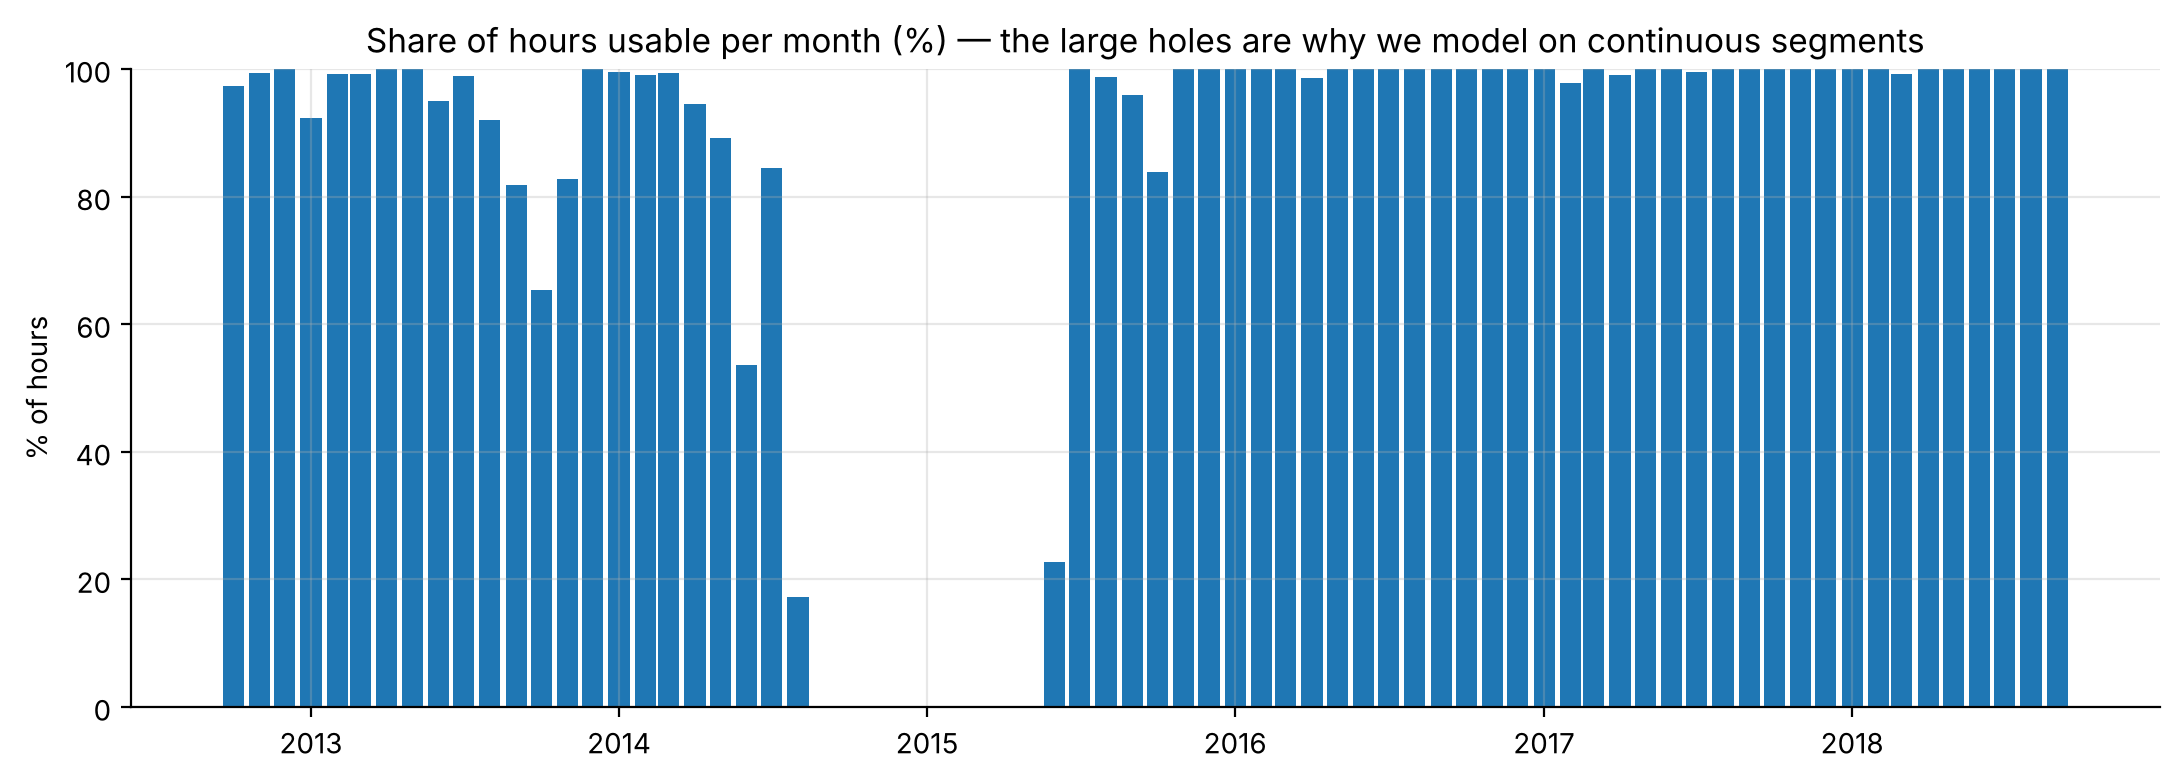

In [ ]:
monthly_usable = hourly["valid"].resample("MS").mean() * 100
fig, ax = plt.subplots()
ax.bar(monthly_usable.index, monthly_usable.values, width=25, color="tab:blue")
ax.set(title="Share of hours usable per month (%) — the large holes are why we model on continuous segments",
       ylabel="% of hours", ylim=(0, 100))
plt.tight_layout()
plt.show()

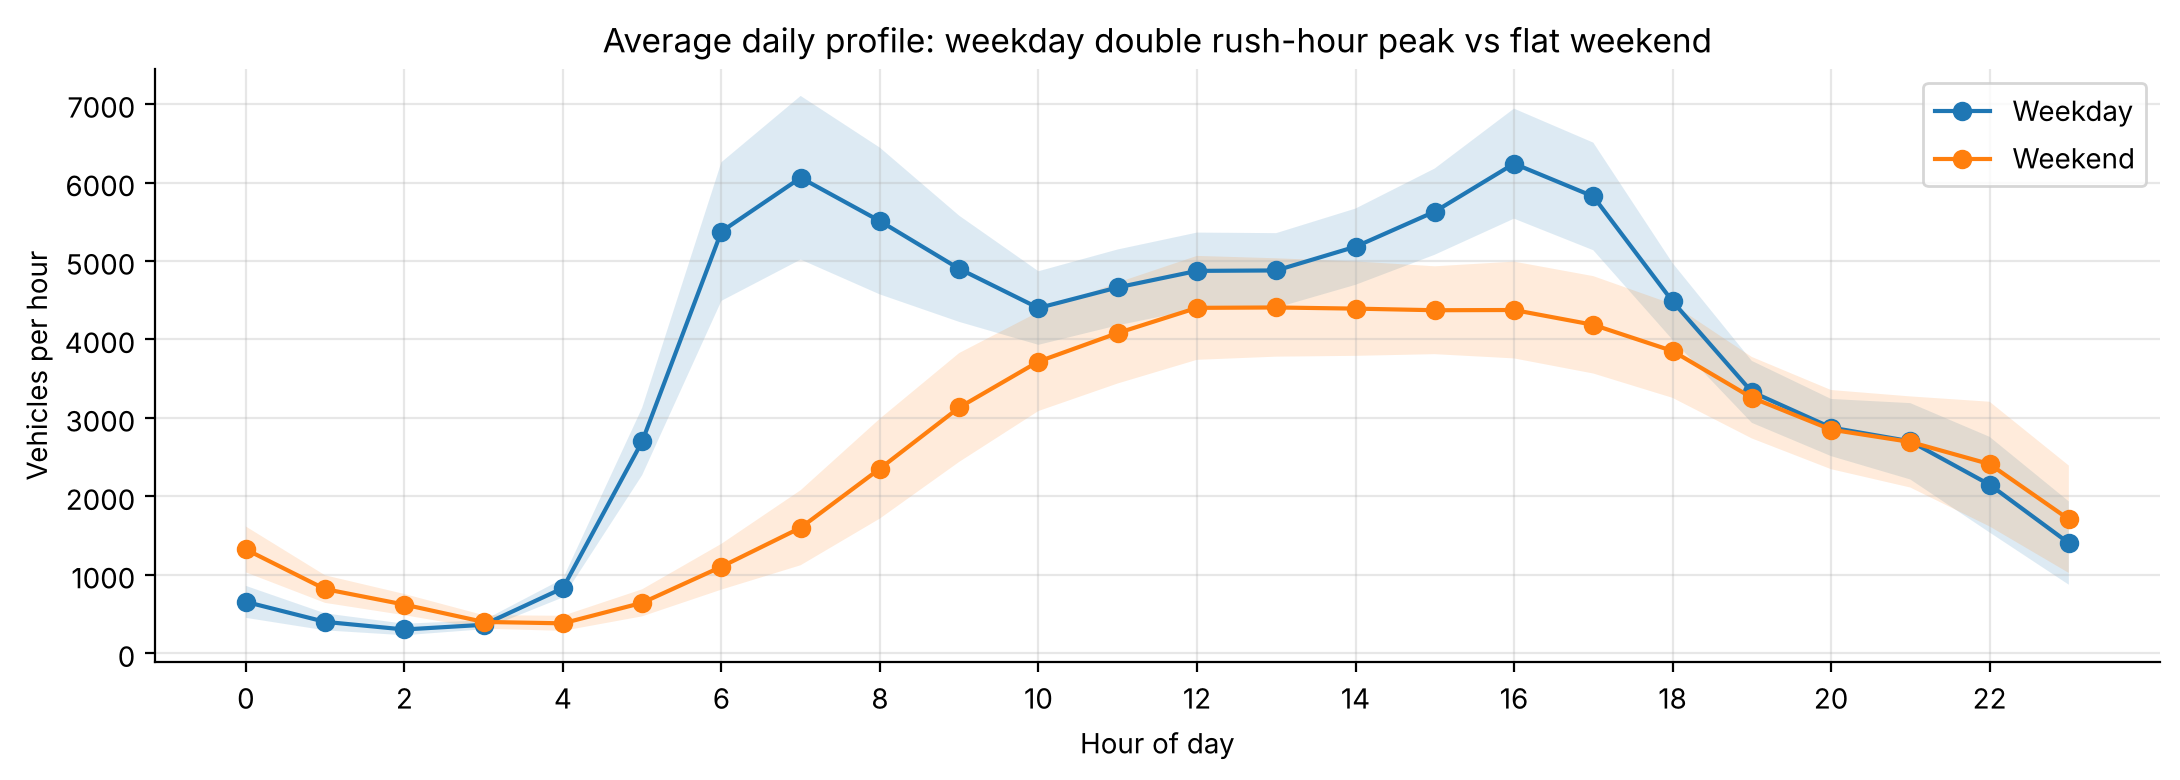

In [ ]:
profile = (hourly[hourly["observed"]]
           .groupby(["is_weekend", "hour"])["traffic_volume"].agg(["mean", "std"]).reset_index())
fig, ax = plt.subplots()
for flag, label in [(0, "Weekday"), (1, "Weekend")]:
    part = profile[profile["is_weekend"] == flag]
    ax.plot(part["hour"], part["mean"], marker="o", label=label)
    ax.fill_between(part["hour"], part["mean"] - part["std"], part["mean"] + part["std"], alpha=0.15)
ax.set(title="Average daily profile: weekday double rush-hour peak vs flat weekend",
       xlabel="Hour of day", ylabel="Vehicles per hour", xticks=range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()

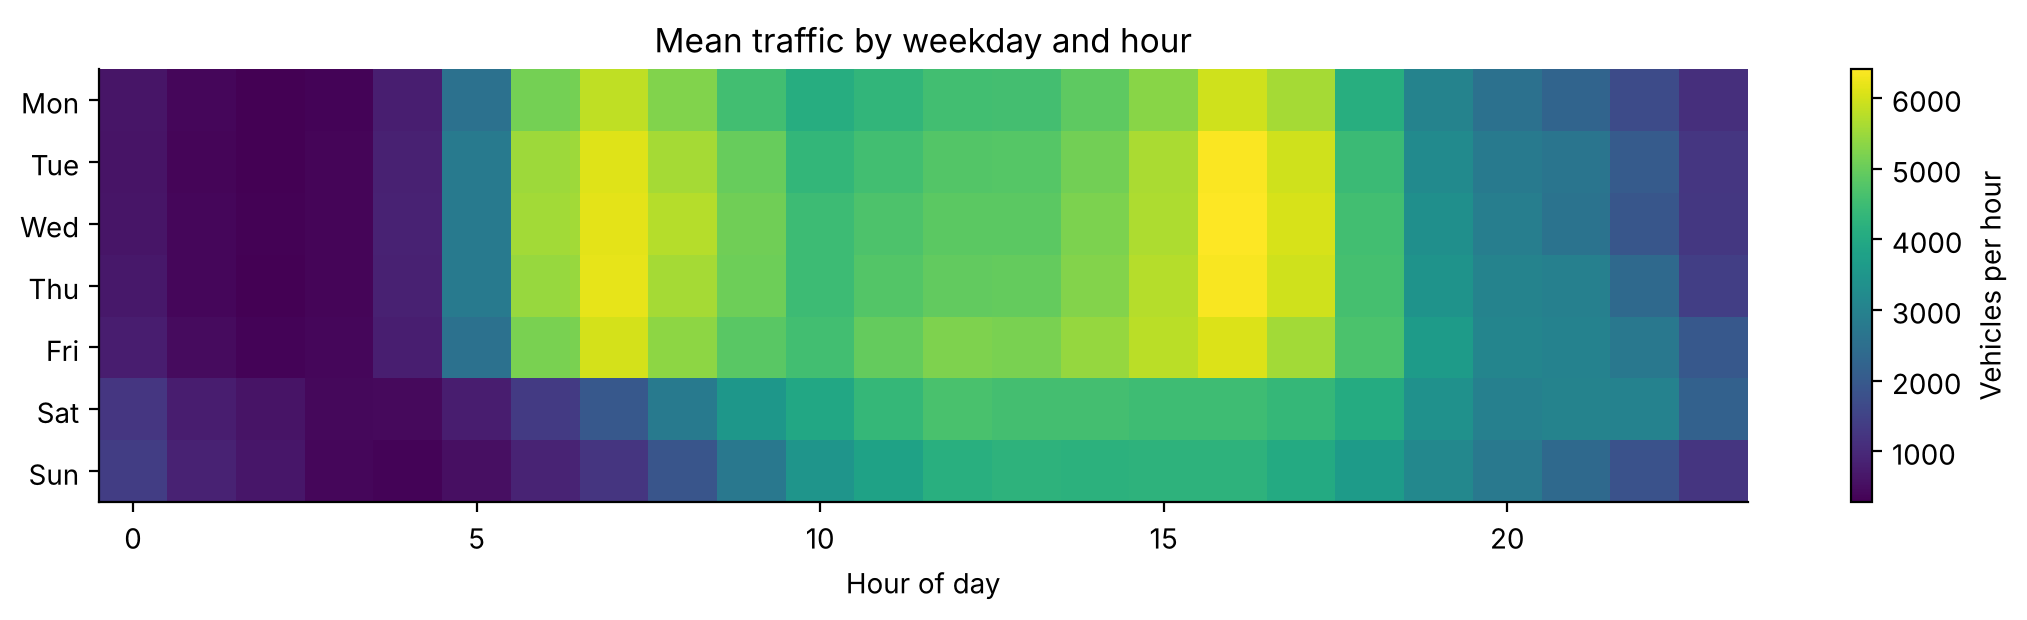

In [ ]:
heat = hourly[hourly["observed"]].pivot_table(index="dayofweek", columns="hour", values="traffic_volume")
fig, ax = plt.subplots(figsize=(11, 3.2))
image = ax.imshow(heat.values, aspect="auto", cmap="viridis")
ax.set(title="Mean traffic by weekday and hour", xlabel="Hour of day", yticks=range(7),
       yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.grid(False)
fig.colorbar(image, ax=ax, label="Vehicles per hour")
plt.tight_layout()
plt.show()

## 5. Evaluation protocol
One protocol for every supervised model, so the numbers in the final table mean the same thing.

* **Chronological split, never shuffled:** first 70 % of usable hours = train, next 15 % = validation,
  last 15 % = test. Validation is for early stopping / model selection; test is touched once per model.
* **Metrics:** MAE, RMSE and sMAPE, implemented by hand below (a few lines each, and no ambiguity about the formula).
* **Baselines:** *seasonal naive* (same hour last week, `t-168`), *last-day naive* (same hour yesterday, `t-24`)
  and, for 1-step forecasts, *persistence* (`t-1`). Every model is scored next to the baselines **on exactly the
  same targets**; the "skill" column in the final table is the MAE improvement over seasonal naive.
* **Observed targets only:** interpolated hours may be used as *inputs*, but they are never counted as test targets.

In [ ]:
@dataclass(frozen=True)
class SplitBoundaries:
    """Last timestamp belonging to the training and the validation period."""
    train_end: pd.Timestamp
    val_end: pd.Timestamp


def chronological_boundaries(hourly: pd.DataFrame, train_frac: float, val_frac: float) -> SplitBoundaries:
    """Cut the *usable* hours at the 70 % and 85 % marks."""
    usable = hourly.index[hourly["valid"]]
    n = len(usable)
    return SplitBoundaries(train_end=usable[int(n * train_frac) - 1],
                           val_end=usable[int(n * (train_frac + val_frac)) - 1])


def split_labels(index: pd.DatetimeIndex, bounds: SplitBoundaries) -> np.ndarray:
    """'train' / 'val' / 'test' label for each timestamp."""
    return np.where(index <= bounds.train_end, "train", np.where(index <= bounds.val_end, "val", "test"))


bounds = chronological_boundaries(hourly, cfg.train_frac, cfg.val_frac)
hourly["split"] = split_labels(hourly.index, bounds)

split_summary = (hourly[hourly["valid"]].groupby("split")
                 .agg(start=("traffic_volume", lambda s: s.index.min()),
                      end=("traffic_volume", lambda s: s.index.max()),
                      hours=("traffic_volume", "size")).loc[["train", "val", "test"]])
split_summary

,start,end,hours
split,,,
train,2012-10-02 09:00:00,2017-04-06 13:00:00,30335
val,2017-04-06 14:00:00,2018-01-02 20:00:00,6500
test,2018-01-02 21:00:00,2018-09-30 23:00:00,6501


In [ ]:
# --- metrics --------------------------------------------------------------------------------
def mae(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.mean(np.abs(y_true - y_pred)))


def rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def smape(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Symmetric MAPE in %. Defined as 0 when both values are 0 (we have a couple of zero-traffic hours)."""
    denom = np.abs(y_true) + np.abs(y_pred)
    ratio = np.divide(2 * np.abs(y_true - y_pred), denom, out=np.zeros_like(denom, dtype=float), where=denom > 0)
    return float(100 * np.mean(ratio))


def score(y_true: np.ndarray, y_pred: np.ndarray, mask: np.ndarray | None = None) -> dict:
    """MAE / RMSE / sMAPE over all (optionally masked) targets, any array shape."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    if mask is not None:
        y_true, y_pred = y_true[mask], y_pred[mask]
    return {"n_targets": int(y_true.size), "MAE": mae(y_true, y_pred),
            "RMSE": rmse(y_true, y_pred), "sMAPE": smape(y_true, y_pred)}

In [ ]:
SEASONAL_NAIVE = "Seasonal naive (t-168)"


class ResultsTracker:
    """Collects one row per (model, test set) so the final comparison is a single table."""

    def __init__(self) -> None:
        self._rows: list[dict] = []
        self._baselined: set[str] = set()

    def add(self, model: str, test_set: str, horizon: str, y_true, y_pred, mask=None, note: str = "") -> dict:
        row = {"model": model, "test_set": test_set, "horizon": horizon, "note": note,
               **score(y_true, y_pred, mask)}
        self._rows.append(row)
        return row

    def add_baselines(self, test_set: str, horizon: str, y_true, baseline_preds: dict, mask=None) -> None:
        """Score the naive baselines once per test set (they depend only on the targets)."""
        if test_set in self._baselined:
            return
        for name, y_pred in baseline_preds.items():
            self.add(name, test_set, horizon, y_true, y_pred, mask, note="baseline")
        self._baselined.add(test_set)

    def table(self) -> pd.DataFrame:
        frame = pd.DataFrame(self._rows)
        reference = frame[frame["model"] == SEASONAL_NAIVE].set_index("test_set")["MAE"]
        frame["skill_vs_seasonal_naive_%"] = 100 * (1 - frame["MAE"] / frame["test_set"].map(reference))
        return frame.sort_values(["test_set", "MAE"]).reset_index(drop=True)


tracker = ResultsTracker()

## 6. Model 1 — Regression: LightGBM (with a Ridge baseline)

**Why gradient boosting here.** Traffic depends on *interactions* — hour × weekday × holiday × weather — that a
linear model cannot express without hand-crafted terms. Trees find them automatically, cope with the mixed numeric /
categorical inputs, ignore outliers, and LightGBM handles missing lag values natively.

**Setup (plan, slide 7).** Target `traffic_volume`. Features: hour, weekday, month, holiday flag, weather, lags
1/2/3/24/168 h and a 24 h rolling mean. Three variants:

| Variant | Features | What it tells us |
|---|---|---|
| `with_lags` | calendar + weather + lags 1–168 h | the main 1-hour-ahead model |
| `no_lags` | calendar + weather only | how much the *weather* alone explains (the plan's no-lag variant) |
| `day_ahead` | calendar + weather + lags ≥ 24 h | the 24-hour-ahead extension: only information available a day earlier |

> **Assumption to keep in mind:** all three use the weather of the target hour itself, i.e. they assume a good
> weather forecast / nowcast is available. The LSTM and PatchTST later use *past* weather only, so compare
> them with care — the table in section 12 labels this.

In [ ]:
CALENDAR_FEATURES = ["hour", "dayofweek", "month", "is_holiday"]
WEATHER_FEATURES = ["temp", "rain_1h", "snow_1h", "clouds_all", "weather_main"]
DAY_AHEAD_LAGS = (24, 48, 168)


def build_tabular_frame(hourly: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    """One row per usable hour with lag features computed *inside each continuous segment*.

    Grouping by `segment_id` is what keeps a lag from reaching across a multi-month gap.
    """
    frame = hourly.loc[hourly["valid"]].copy()
    by_segment = frame.groupby("segment_id")["traffic_volume"]

    for lag in sorted(set(cfg.lag_hours) | set(DAY_AHEAD_LAGS)):
        frame[f"lag_{lag}"] = by_segment.shift(lag)

    # mean of the 24 hours *before* t, and the same window ending 24 h earlier (available a day ahead)
    window = cfg.rolling_window
    frame[f"roll_mean_{window}"] = by_segment.transform(lambda s: s.shift(1).rolling(window).mean())
    frame[f"roll_mean_{window}_d1"] = by_segment.transform(lambda s: s.shift(24).rolling(window).mean())
    return frame


tabular = build_tabular_frame(hourly, cfg)

# One fixed category list (a vocabulary, not a statistic) so train / val / test share the same integer codes.
weather_categories = sorted(tabular["weather_main"].unique())
tabular["weather_main"] = tabular["weather_main"].astype(pd.CategoricalDtype(weather_categories))

roll = f"roll_mean_{cfg.rolling_window}"
FEATURE_SETS = {
    "with_lags": dict(
        horizon="1 h", note="concurrent weather; lags 1,2,3,24,168 + 24 h mean",
        columns=CALENDAR_FEATURES + WEATHER_FEATURES + [f"lag_{k}" for k in cfg.lag_hours] + [roll]),
    "no_lags": dict(
        horizon="n/a", note="weather + calendar only (no traffic history)",
        columns=CALENDAR_FEATURES + WEATHER_FEATURES),
    "day_ahead": dict(
        horizon="24 h", note="concurrent weather; lags >= 24 h only",
        columns=CALENDAR_FEATURES + WEATHER_FEATURES + [f"lag_{k}" for k in DAY_AHEAD_LAGS] + [f"{roll}_d1"]),
}

# Targets: observed hours only (never train on or score interpolated values).
is_observed = tabular["observed"]
train_rows = tabular[(tabular["split"] == "train") & is_observed]
val_rows = tabular[(tabular["split"] == "val") & is_observed]
# Test rows must have a full week of history so the seasonal-naive baseline exists on the very same rows.
test_rows = tabular[(tabular["split"] == "test") & is_observed & tabular["lag_168"].notna()]
print(f"train {len(train_rows):,} | val {len(val_rows):,} | test {len(test_rows):,} rows")

train 27,593 | val 6,484 | test 6,321 rows


In [ ]:
TEST_HOURS = "Test hours (single-step & day-ahead)"
y_test_hours = test_rows["traffic_volume"].to_numpy()

tracker.add_baselines(
    TEST_HOURS, horizon="1 h", y_true=y_test_hours,
    baseline_preds={SEASONAL_NAIVE: test_rows["lag_168"].to_numpy(),
                    "Last-day naive (t-24)": test_rows["lag_24"].to_numpy(),
                    "Persistence (t-1)": test_rows["lag_1"].to_numpy()})
tracker.table().query("test_set == @TEST_HOURS")[["model", "MAE", "RMSE", "sMAPE"]]

,model,MAE,RMSE,sMAPE
0,Seasonal naive (t-168),339.585509,651.358992,12.375920
1,Last-day naive (t-24),562.099905,1025.676988,21.409779
2,Persistence (t-1),587.798291,812.910866,26.112687


In [ ]:
def fit_lightgbm(columns: list[str], cfg: Config) -> lgb.LGBMRegressor:
    """Train one LightGBM regressor; the validation set decides when to stop adding trees."""
    model = lgb.LGBMRegressor(
        n_estimators=50 if cfg.fast_dev_run else 3000, learning_rate=0.03, num_leaves=63,
        min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=cfg.seed, n_jobs=-1, verbose=-1)
    model.fit(train_rows[columns], train_rows["traffic_volume"],
              eval_set=[(val_rows[columns], val_rows["traffic_volume"])], eval_metric="l1",
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model


lgbm_models, lgbm_predictions = {}, {}
for name, spec in FEATURE_SETS.items():
    model = fit_lightgbm(spec["columns"], cfg)
    prediction = model.predict(test_rows[spec["columns"]])
    lgbm_models[name], lgbm_predictions[name] = model, prediction
    row = tracker.add(f"LightGBM [{name}]", TEST_HOURS, spec["horizon"], y_test_hours, prediction, note=spec["note"])
    print(f"{name:10s} trees={model.best_iteration_ or model.n_estimators_:5d}  "
          f"MAE={row['MAE']:7.1f}  RMSE={row['RMSE']:7.1f}  sMAPE={row['sMAPE']:5.2f}%")

with_lags  trees=  776  MAE=  141.1  RMSE=  217.8  sMAPE= 5.66%


no_lags    trees=  325  MAE=  229.7  RMSE=  363.9  sMAPE= 9.96%


day_ahead  trees=  410  MAE=  213.8  RMSE=  360.6  sMAPE= 8.60%


### Ridge baseline
The plan lists Ridge as the *simple* baseline for the regression family. Linear models need explicit encodings, so
we one-hot encode hour, weekday and weather, standardise the numeric columns with **training** statistics only,
and drop the (few) rows with an incomplete lag history.

In [ ]:
RIDGE_NUMERIC = ["temp", "rain_1h", "snow_1h", "clouds_all", *[f"lag_{k}" for k in cfg.lag_hours], roll]
RIDGE_CATEGORICAL = ["hour", "dayofweek", "weather_main"]


def ridge_design_matrix(frame: pd.DataFrame, stats: tuple | None = None, columns: pd.Index | None = None):
    """Numeric columns standardised (train mean / std), categoricals one-hot, plus the holiday flag."""
    numeric = frame[RIDGE_NUMERIC].astype(float)
    stats = stats or (numeric.mean(), numeric.std())
    numeric = (numeric - stats[0]) / stats[1]
    dummies = pd.get_dummies(frame[RIDGE_CATEGORICAL].astype(str), dtype=float)
    design = pd.concat([numeric, dummies, frame[["is_holiday"]].astype(float)], axis=1)
    if columns is not None:
        design = design.reindex(columns=columns, fill_value=0.0)   # same columns as in training
    return design, stats


ridge_train = train_rows.dropna(subset=RIDGE_NUMERIC)
X_ridge_train, ridge_stats = ridge_design_matrix(ridge_train)
ridge = Ridge(alpha=1.0).fit(X_ridge_train, ridge_train["traffic_volume"])

X_ridge_test, _ = ridge_design_matrix(test_rows, ridge_stats, X_ridge_train.columns)
ridge_prediction = ridge.predict(X_ridge_test)
row = tracker.add("Ridge (linear baseline)", TEST_HOURS, "1 h", y_test_hours, ridge_prediction,
                  note="one-hot calendar + lags + weather")
print(f"Ridge  MAE={row['MAE']:.1f}  RMSE={row['RMSE']:.1f}  sMAPE={row['sMAPE']:.2f}%")

Ridge  MAE=237.0  RMSE=339.3  sMAPE=11.53%


### What did LightGBM learn?
Gain importance says which features the trees relied on; the error-by-hour plot shows *when* the model struggles.

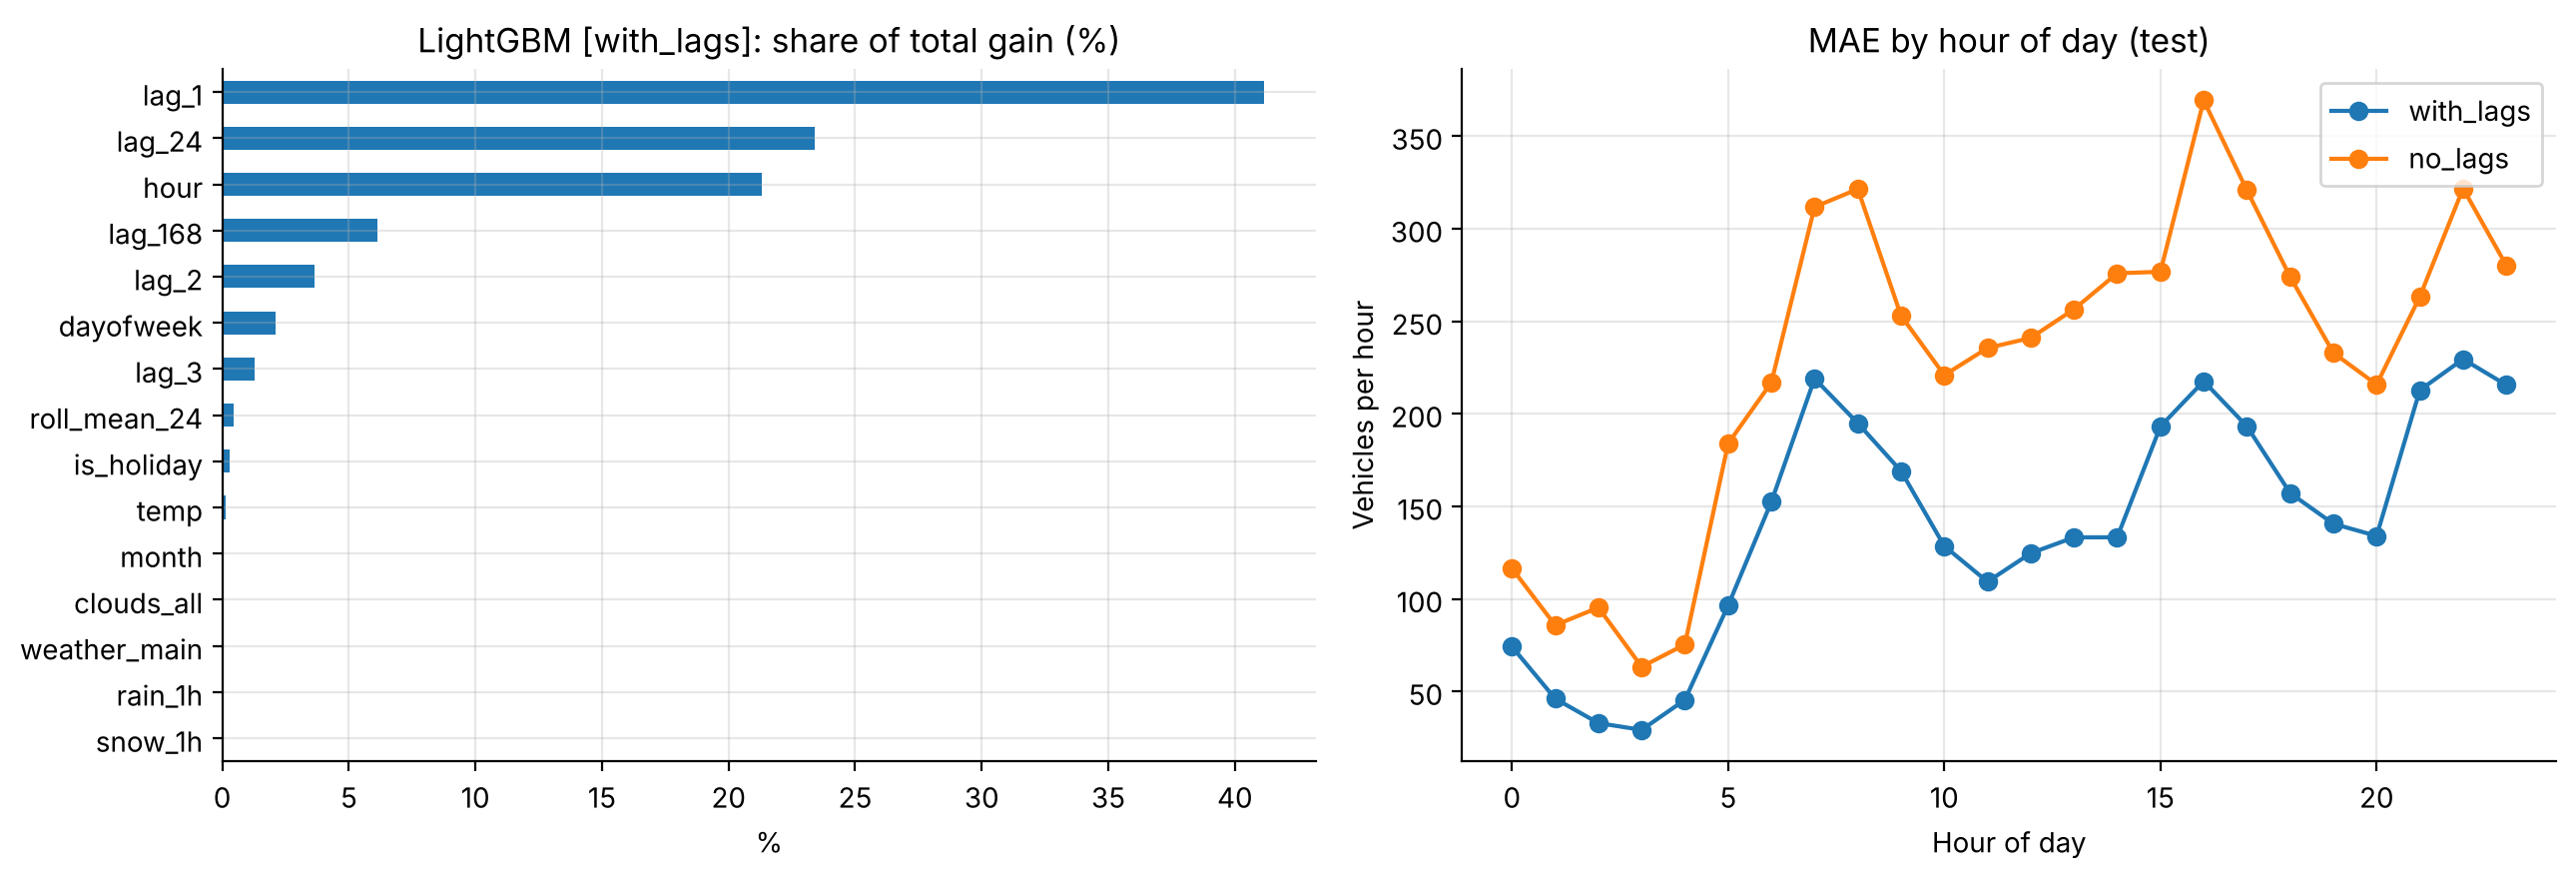

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

booster = lgbm_models["with_lags"].booster_
importance = pd.Series(booster.feature_importance("gain"), index=booster.feature_name()).sort_values()
(importance / importance.sum() * 100).plot.barh(ax=axes[0], color="tab:blue")
axes[0].set(title="LightGBM [with_lags]: share of total gain (%)", xlabel="%")

abs_error = pd.DataFrame({"hour": test_rows["hour"].to_numpy(),
                          "with_lags": np.abs(y_test_hours - lgbm_predictions["with_lags"]),
                          "no_lags": np.abs(y_test_hours - lgbm_predictions["no_lags"])})
abs_error.groupby("hour").mean().plot(ax=axes[1], marker="o")
axes[1].set(title="MAE by hour of day (test)", xlabel="Hour of day", ylabel="Vehicles per hour")
plt.tight_layout()
plt.show()

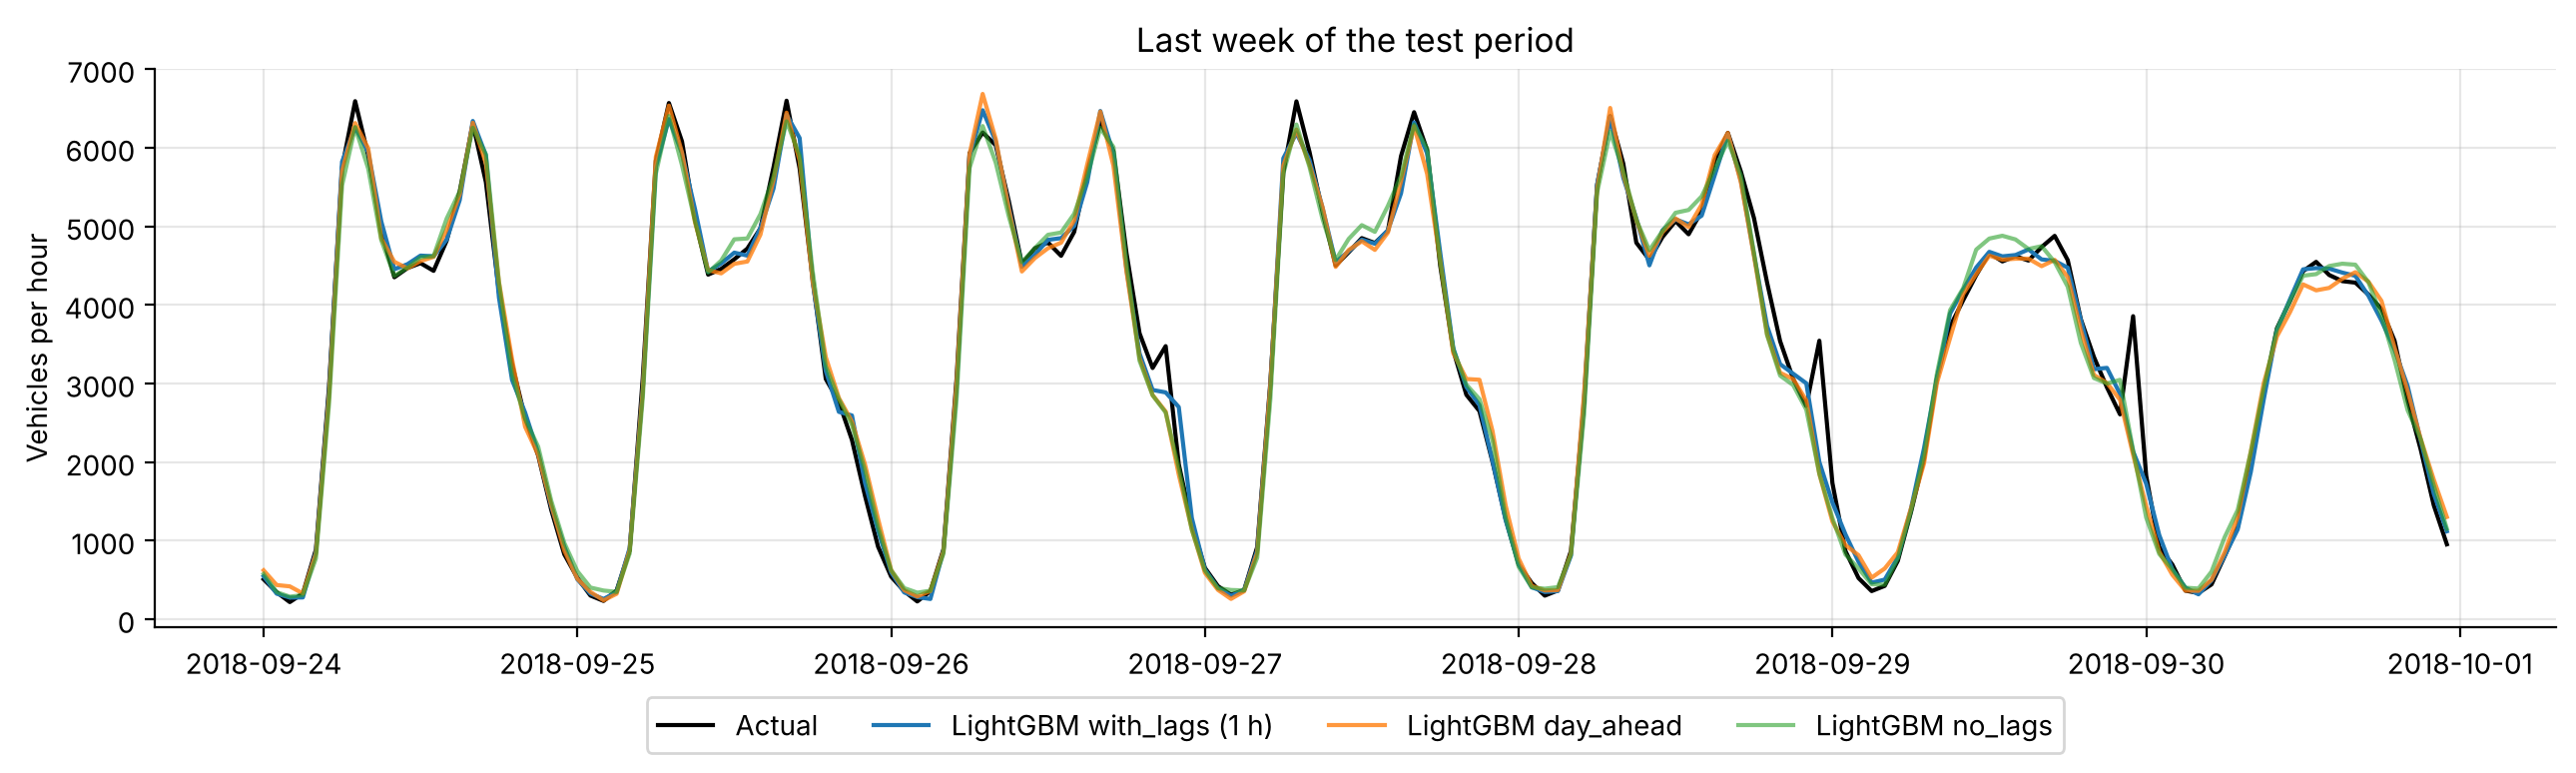

In [ ]:
last_week = slice(-168, None)    # the final week of the test period
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test_rows.index[last_week], y_test_hours[last_week], color="black", lw=1.5, label="Actual")
ax.plot(test_rows.index[last_week], lgbm_predictions["with_lags"][last_week], label="LightGBM with_lags (1 h)")
ax.plot(test_rows.index[last_week], lgbm_predictions["day_ahead"][last_week], label="LightGBM day_ahead", alpha=0.8)
ax.plot(test_rows.index[last_week], lgbm_predictions["no_lags"][last_week], label="LightGBM no_lags", alpha=0.6)
ax.set(title="Last week of the test period", ylabel="Vehicles per hour")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

**Reading the results.** `with_lags` should beat every naive baseline because the previous hours carry most of
the information. `no_lags` shows how far calendar + weather alone gets you — usually respectable (the daily
and weekly rhythm is in the calendar), with weather adding a smaller, second-order effect.
The error-by-hour plot typically peaks at the morning and evening rush hours, where traffic changes fastest.

## 7. Model 2 — Clustering: K-Means on daily profiles

**Why clustering a time series?** A day is a 24-dimensional vector (its hourly volumes). Weekdays have a double
rush-hour peak, weekends a flat midday hump, holidays and snow days look different again. K-Means should
rediscover these regimes **without being told the calendar**, and we then *check* it against the calendar and the weather.
This is exploratory — there is no forecast and no test set. The cluster label can later be used as a feature in
the supervised models.

**Design choices**
* Only **complete observed days** (all 24 hours really measured) are used — no interpolated values.
* Scaling: the plan says "standardised". We standardise with a *single* mean and standard deviation for the whole
  matrix (`cluster_scaling="global"`). Z-scoring every hour separately would give the quiet night hours (small
  variance) the same weight as the rush hours and tends to cluster on noise; set `cluster_scaling="per_hour"` to compare.
* `k` is chosen from the elbow (inertia) and silhouette plots below.

In [ ]:
def build_daily_profiles(hourly: pd.DataFrame) -> pd.DataFrame:
    """Rows = complete days (24 observed hours), columns = hour 0..23, values = vehicles per hour."""
    observed = hourly[hourly["observed"]]
    profiles = observed.pivot_table(index=observed.index.normalize(), columns="hour", values="traffic_volume")
    return profiles.dropna()


def standardise_profiles(profiles: np.ndarray, mode: str) -> np.ndarray:
    if mode == "global":
        return (profiles - profiles.mean()) / profiles.std()
    if mode == "per_hour":
        return (profiles - profiles.mean(axis=0)) / profiles.std(axis=0)
    raise ValueError(f"unknown cluster_scaling: {mode!r}")


daily_profiles = build_daily_profiles(hourly)
X_days = standardise_profiles(daily_profiles.to_numpy(dtype=float), cfg.cluster_scaling)
print(f"{len(daily_profiles):,} complete days (plan: 1,214), {X_days.shape[1]} features each")

1,214 complete days (plan: 1,214), 24 features each


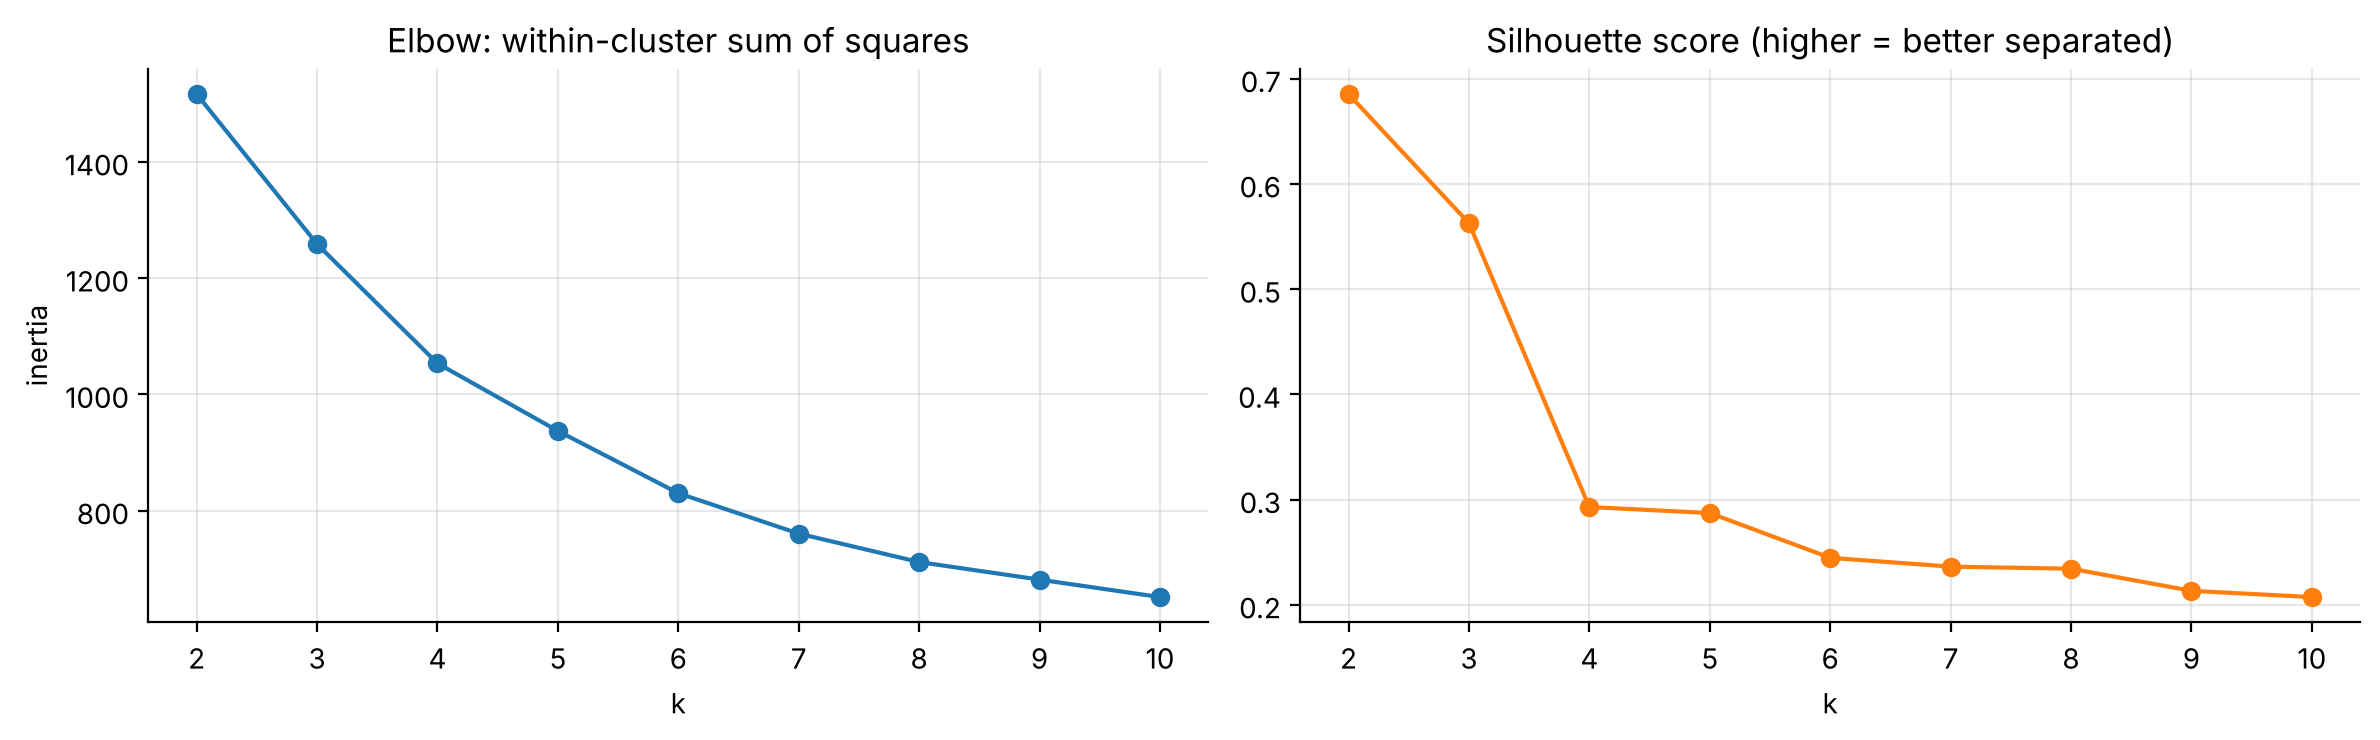

 k  inertia  silhouette
 2   1516.0       0.685
 3   1258.0       0.563
 4   1053.0       0.293
 5    937.0       0.287
 6    830.0       0.245
 7    760.0       0.236
 8    711.0       0.234
 9    681.0       0.213
10    651.0       0.207


In [ ]:
k_values = range(2, 11)
inertias, silhouettes = [], []
for k in k_values:
    fitted = KMeans(n_clusters=k, n_init=10, random_state=cfg.seed).fit(X_days)
    inertias.append(fitted.inertia_)
    silhouettes.append(silhouette_score(X_days, fitted.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set(title="Elbow: within-cluster sum of squares", xlabel="k", ylabel="inertia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="tab:orange")
axes[1].set(title="Silhouette score (higher = better separated)", xlabel="k")
plt.tight_layout()
plt.show()
print(pd.DataFrame({"k": list(k_values), "inertia": np.round(inertias), "silhouette": np.round(silhouettes, 3)}).to_string(index=False))

**Choosing k.** Silhouette alone tends to favour the coarsest split (weekday vs weekend, k = 2). The plan
expects *more* structure — weekday, weekend and an unusual-day cluster — so we look for the elbow *and* a
silhouette that has not collapsed. The choice is stored in `Config.n_clusters` so it is explicit and easy to change.

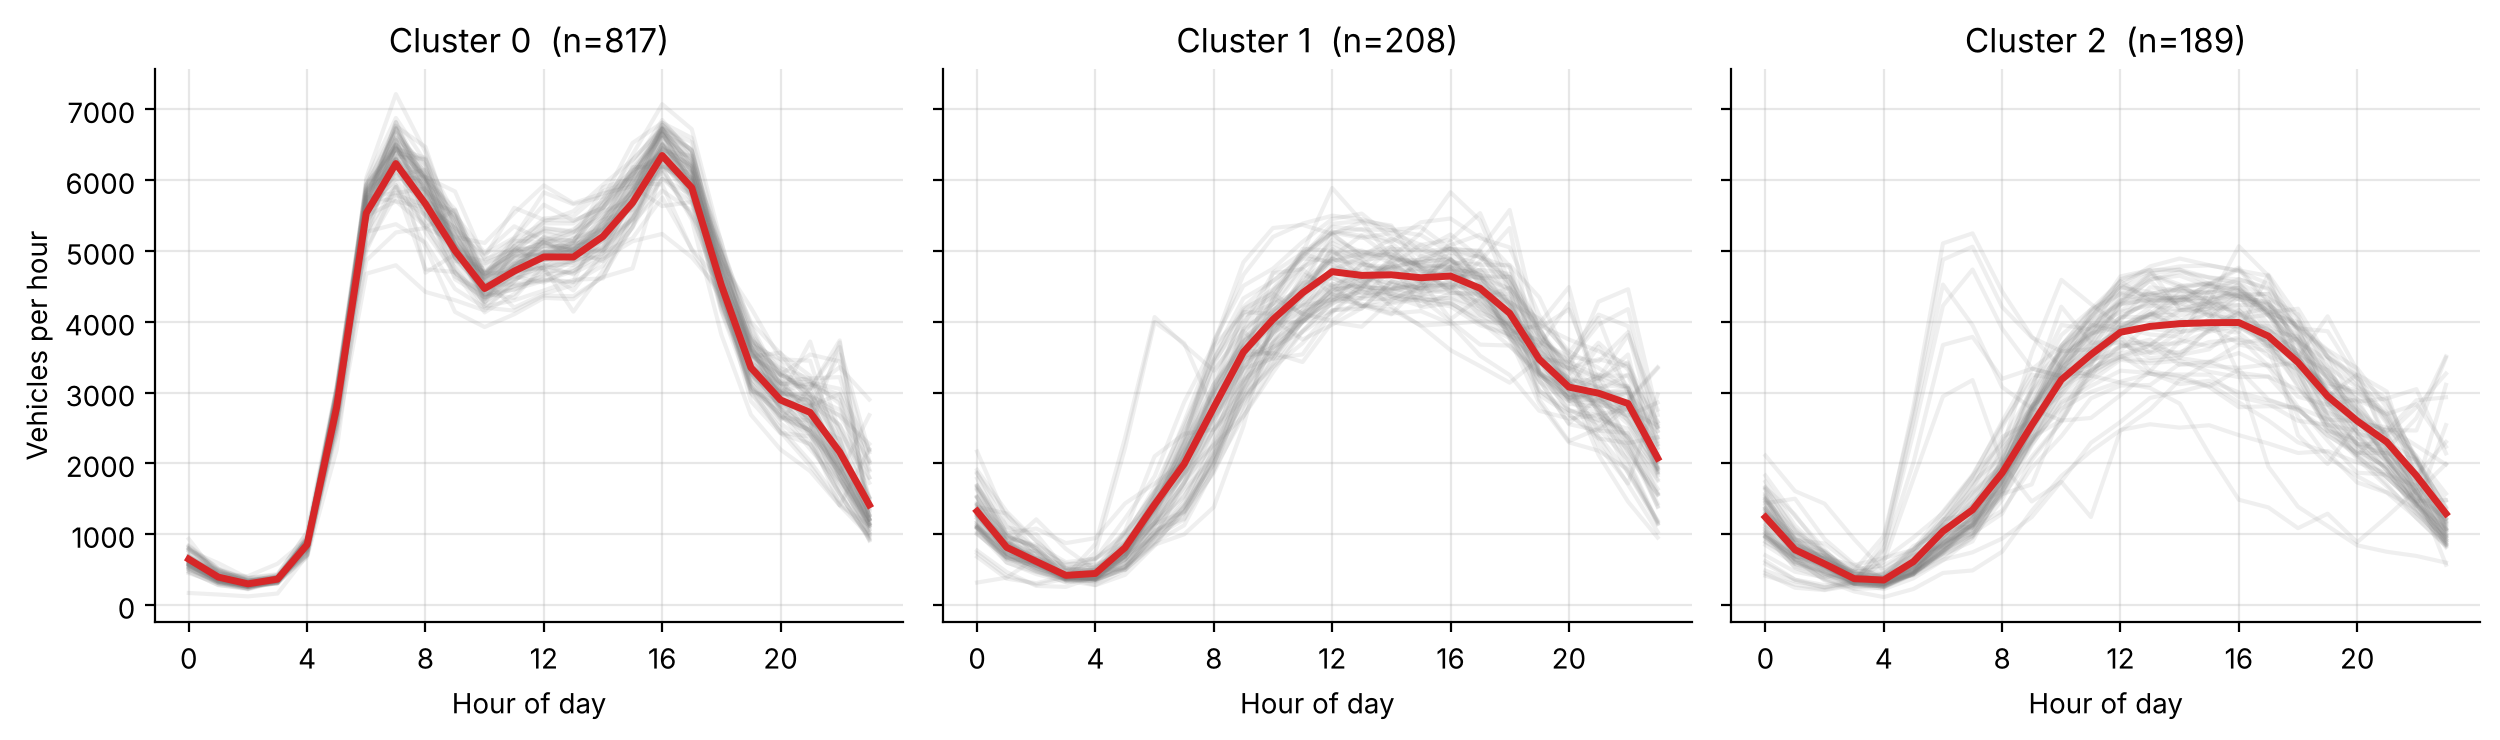

In [ ]:
kmeans = KMeans(n_clusters=cfg.n_clusters, n_init=20, random_state=cfg.seed).fit(X_days)

# Relabel clusters by mean daily volume (0 = busiest) so cluster names are stable between runs.
volume_rank = daily_profiles.to_numpy().mean(axis=1)
cluster_means = np.array([volume_rank[kmeans.labels_ == c].mean() for c in range(cfg.n_clusters)])
relabel = {old: new for new, old in enumerate(np.argsort(-cluster_means))}
day_cluster = pd.Series([relabel[c] for c in kmeans.labels_], index=daily_profiles.index, name="cluster")

fig, axes = plt.subplots(1, cfg.n_clusters, figsize=(4.2 * cfg.n_clusters, 3.8), sharey=True)
for cluster, ax in zip(range(cfg.n_clusters), np.atleast_1d(axes)):
    members = daily_profiles[day_cluster == cluster]
    for _, day in members.sample(min(60, len(members)), random_state=cfg.seed).iterrows():
        ax.plot(day.index, day.values, color="grey", alpha=0.12)
    ax.plot(members.columns, members.mean(), color="tab:red", lw=2.5)
    ax.set(title=f"Cluster {cluster}  (n={len(members)})", xlabel="Hour of day", xticks=range(0, 24, 4))
np.atleast_1d(axes)[0].set_ylabel("Vehicles per hour")
plt.tight_layout()
plt.show()

### Do the clusters mean something?
We never gave K-Means the weekday, holiday or weather — so agreement with them is real evidence that the
clusters capture genuine day types.

In [ ]:
daily_meta = (hourly.groupby(hourly.index.normalize())
              .agg(dayofweek=("dayofweek", "first"), month=("month", "first"),
                   is_holiday=("is_holiday", "max"), mean_temp=("temp", "mean"),
                   snow_hours=("weather_main", lambda s: int((s == "Snow").sum()))))
cluster_report = daily_meta.loc[day_cluster.index].assign(cluster=day_cluster, is_weekend=lambda d: (d["dayofweek"] >= 5).astype(int))

summary = cluster_report.groupby("cluster").agg(
    days=("is_weekend", "size"), weekend_share=("is_weekend", "mean"), holiday_share=("is_holiday", "mean"),
    snow_hours_per_day=("snow_hours", "mean"), mean_temp_K=("mean_temp", "mean"))
summary["mean_daily_volume"] = daily_profiles.groupby(day_cluster).mean().sum(axis=1)
print(summary.round(2).to_string())

print("Day-of-week composition of each cluster (rows = cluster):")
print(pd.crosstab(cluster_report["cluster"], cluster_report["dayofweek"].map(dict(enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])))
                  ).reindex(columns=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]).to_string())

ari = adjusted_rand_score(cluster_report["is_weekend"], cluster_report["cluster"])
print(f"\nAdjusted Rand index vs the weekday/weekend label: {ari:.2f}  (1 = identical partition, 0 = random)")

         days  weekend_share  holiday_share  snow_hours_per_day  mean_temp_K  mean_daily_volume
cluster                                                                                        
0         817           0.00           0.01                0.67       282.74           87025.28
1         208           0.94           0.01                0.61       283.48           69021.60
2         189           0.84           0.12                0.72       280.58           55401.55
Day-of-week composition of each cluster (rows = cluster):
dayofweek  Mon  Tue  Wed  Thu  Fri  Sat  Sun
cluster                                     
0          159  166  162  166  164    0    0
1            2    2    0    2    6  156   40
2           18    4    1    4    3   23  136

Adjusted Rand index vs the weekday/weekend label: 0.80  (1 = identical partition, 0 = random)


**What K-Means found (k = 3).**
* **Cluster 0 — weekdays** (817 days): contains *every* Monday–Friday that is not unusual and *no* weekend day; the double rush-hour peak at 7 am and 4–5 pm.
* **Cluster 1 — Saturdays** (208 days, 94 % weekend): one broad midday hump, no commute peaks.
* **Cluster 2 — Sundays and holidays** (189 days): the quietest profile; its holiday share (12 %) is ~12× higher than in the other clusters, and it also absorbs 18 weekday Mondays (mostly holidays).

The partition agrees strongly with the calendar (adjusted Rand 0.80 vs weekday/weekend) even though the calendar was never an input. Snow does **not** form its own cluster at k = 3 (snow hours per day are similar in all three), and silhouette collapses at k ≥ 4, so the plan's "snow-day" cluster is not supported by this data; a larger k mostly splits noise.
The labels are saved to `outputs/daily_cluster_labels.csv` and can be joined to the hourly data as a feature.

In [ ]:
day_cluster.to_csv(Path(cfg.output_dir) / "daily_cluster_labels.csv")   # reusable as a feature for later models

## 8. Model 3 — Statistical: SARIMAX (seasonal period 24) with Holt-Winters as baseline

**Why SARIMAX.** The series is dominated by a 24-hour cycle plus weather and holiday effects. SARIMAX models
exactly that — an ARMA structure on the (seasonally) differenced series, plus a regression on exogenous variables —
and its coefficients are interpretable. Holt-Winters (additive seasonality) is the classical seasonal baseline.

**Practical constraint.** SARIMAX needs one *unbroken* series, so, as the plan says, it is fitted on the **longest
stretch with no missing hour at all**. The split is again 70 / 15 / 15 within that stretch.

**Procedure**
1. Choose differencing orders `d`, `D` with the ADF test and the strength of the 24 h autocorrelation.
2. Inspect ACF / PACF to bound the AR / MA orders, then pick the order with the lowest **AIC** on the training part.
3. Re-estimate on train + validation and evaluate on the test part with **rolling 24-hour-ahead forecasts**
   (new origin every few hours, parameters fixed, history updated with what has actually been observed).

Three variants are reported, because they answer different questions:
* **SARIMA** — no exogenous inputs. With `s = 24` alone the model cannot tell a Saturday from a Friday.
* **SARIMAX (calendar)** — adds a weekend flag, a holiday flag and *weekend × hour-of-day* harmonics (Fourier
  terms). A weekend differs from a weekday in **shape** (no rush-hour peaks), not just in level, so a bare flag is
  not enough. All of these are known in advance, so this is a fully honest forecasting model. (A weekly period
  `s = 168` would also fix the problem but makes the state space far too large.)
* **SARIMAX (calendar + weather)** — additionally uses temperature, rain and snow **with the actual future values**:
  a perfect-forecast upper bound, because the plan notes that real weather is observed, not forecast.

In [ ]:
def longest_observed_run(hourly: pd.DataFrame) -> pd.DataFrame:
    """Slice of the hourly frame covering the longest run of hours with a *real* measurement."""
    observed = hourly["observed"]
    run_id = (observed != observed.shift()).cumsum()
    lengths = observed[observed].groupby(run_id[observed]).size()
    members = run_id[observed & (run_id == lengths.idxmax())].index
    return hourly.loc[members.min(): members.max()]


stretch = longest_observed_run(hourly)
y_stretch = stretch["traffic_volume"]
n_stretch = len(y_stretch)
n_train = int(n_stretch * cfg.train_frac)
n_val_end = int(n_stretch * (cfg.train_frac + cfg.val_frac))
print(f"Stretch: {stretch.index[0]} -> {stretch.index[-1]}  ({n_stretch:,} h; plan: 13 Apr - 2 Jul 2017, 1,915 h)")
print(f"train {n_train:,} h | validation {n_val_end - n_train:,} h | test {n_stretch - n_val_end:,} h")

Stretch: 2017-04-13 10:00:00 -> 2017-07-02 04:00:00  (1,915 h; plan: 13 Apr - 2 Jul 2017, 1,915 h)
train 1,340 h | validation 287 h | test 288 h


### Step 1 — Differencing
ADF tests the null hypothesis "the series has a unit root". A small p-value (< 0.05) means the series is already
stationary and needs no further differencing. The autocorrelation at lag 24 tells us how strong the daily cycle is.

In [ ]:
def adf_pvalue(series: pd.Series) -> float:
    return float(adfuller(series.dropna(), autolag="AIC")[1])


def choose_differencing(y: pd.Series, season: int, alpha: float = 0.05) -> tuple[int, int, pd.DataFrame]:
    """Pick (d, D). D = 1 when the daily cycle is strong (lag-24 autocorrelation > 0.5);
    then add ordinary differences until the ADF test rejects a unit root."""
    seasonal_strength = acf(y, nlags=season)[season]
    D = int(seasonal_strength > 0.5)
    candidate = y.diff(season) if D else y
    d, report = 0, []
    while True:
        p_value = adf_pvalue(candidate)
        report.append({"seasonal diffs (D)": D, "ordinary diffs (d)": d, "ADF p-value": p_value})
        if p_value <= alpha or d == 2:
            break
        candidate, d = candidate.diff(), d + 1
    print(f"Lag-{season} autocorrelation of the level series: {seasonal_strength:.2f}")
    return d, D, pd.DataFrame(report)


y_train = y_stretch.iloc[:n_train]
d, D, adf_report = choose_differencing(y_train, cfg.season_length)
print(f"ADF p-value of the raw level series: {adf_pvalue(y_train):.4f}")
print(adf_report.to_string(index=False))
print(f"-> d = {d}, D = {D}")

Lag-24 autocorrelation of the level series: 0.86
ADF p-value of the raw level series: 0.0071
 seasonal diffs (D)  ordinary diffs (d)  ADF p-value
                  1                   0 6.304239e-13
-> d = 0, D = 1


### Step 2 — ACF / PACF and order selection
On the differenced series, spikes at the first lags suggest the non-seasonal `p`, `q`; spikes at lags 24, 48 suggest
the seasonal `P`, `Q`. The plots bound a small candidate grid, which AIC then ranks.

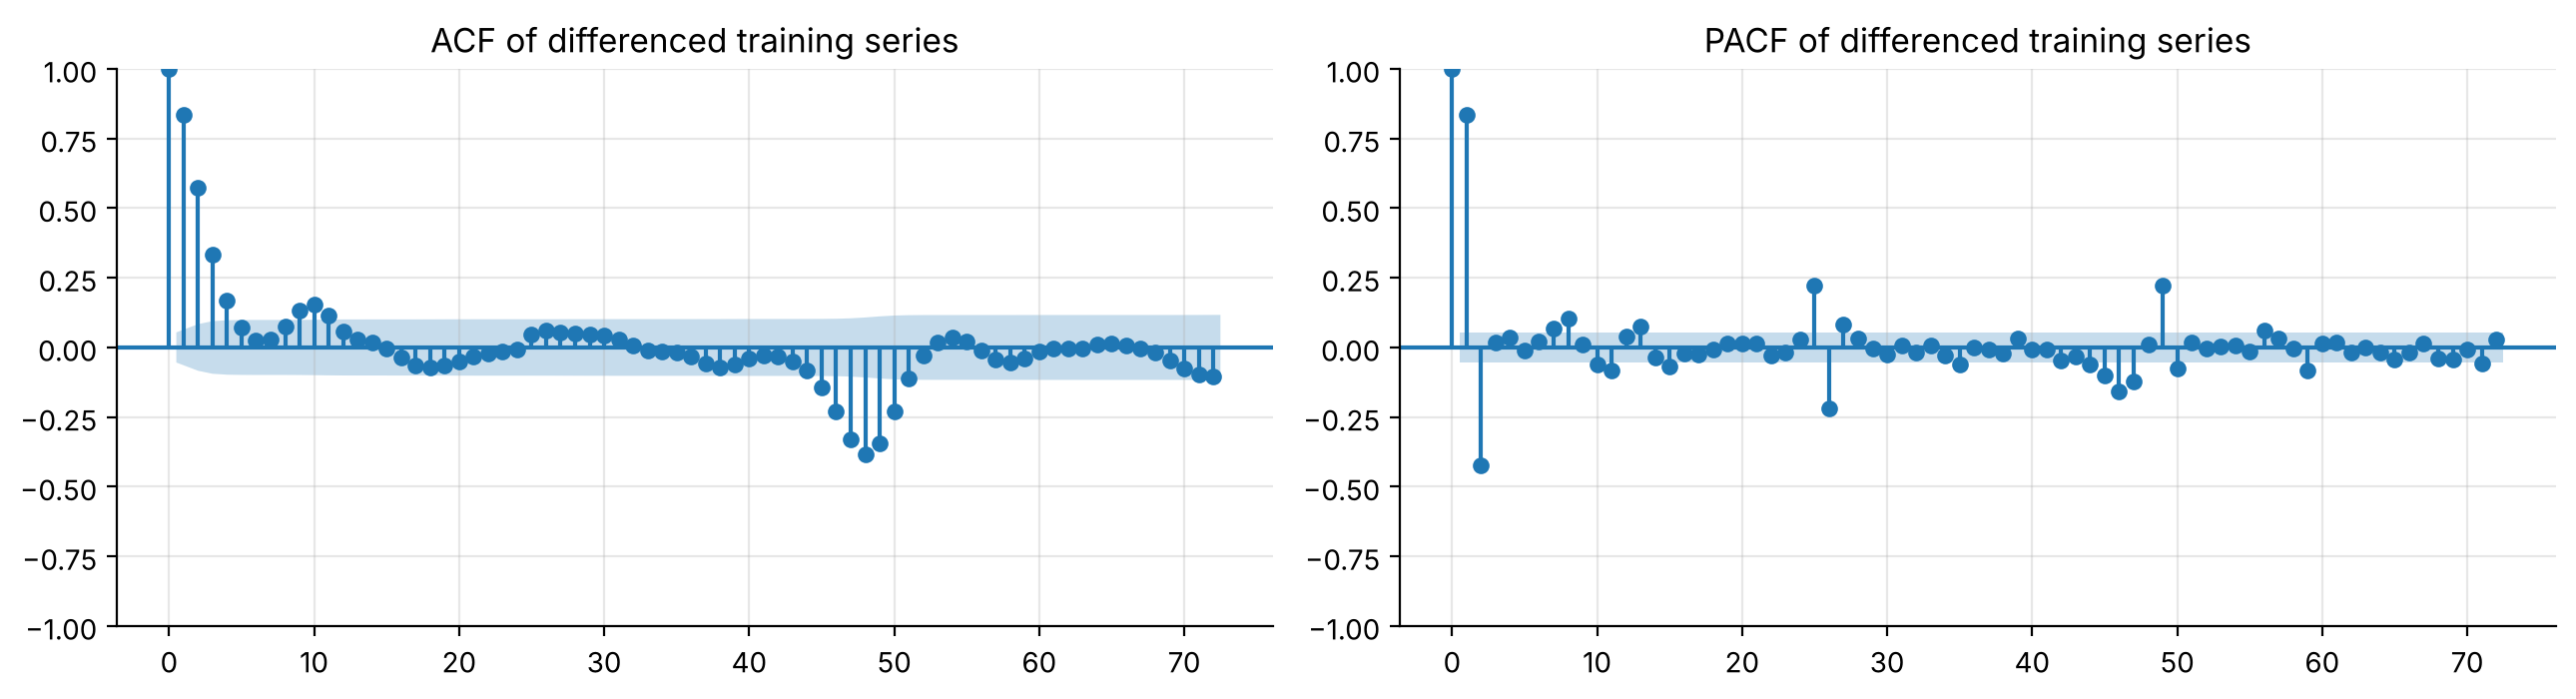

In [ ]:
stationary_train = y_train.diff(cfg.season_length).dropna() if D else y_train
if d:
    stationary_train = stationary_train.diff(d).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
plot_acf(stationary_train, lags=72, ax=axes[0], title="ACF of differenced training series")
plot_pacf(stationary_train, lags=72, ax=axes[1], method="ywm", title="PACF of differenced training series")
plt.tight_layout()
plt.show()

In [ ]:
def weekend_hour_harmonics(frame: pd.DataFrame, n_harmonics: int) -> pd.DataFrame:
    """sin / cos of the hour of day (1..K harmonics), switched on only at weekends: lets the model learn a
    different daily *shape* for Saturday / Sunday."""
    columns = {}
    for k in range(1, n_harmonics + 1):
        angle = 2 * np.pi * k * frame["hour"] / 24
        columns[f"weekend_sin{k}"] = np.sin(angle) * frame["is_weekend"]
        columns[f"weekend_cos{k}"] = np.cos(angle) * frame["is_weekend"]
    return pd.DataFrame(columns, index=frame.index)


# Exogenous inputs: the plan's holiday / temp / rain / snow, plus the weekend terms above. Columns that never vary
# in the training part (here rain and snow: the chosen stretch is dry) carry no information and make the regression
# singular, so they are dropped automatically.
CALENDAR_EXOG = ["is_weekend", "is_holiday"]
WEATHER_EXOG = ["temp", "rain_1h", "snow_1h"]
exog_raw = pd.concat([stretch[CALENDAR_EXOG], weekend_hour_harmonics(stretch, cfg.weekend_harmonics),
                      stretch[WEATHER_EXOG]], axis=1).astype(float)
calendar_names = [c for c in exog_raw if c not in WEATHER_EXOG]
constant_columns = [c for c in exog_raw if exog_raw[c].iloc[:n_train].std() == 0]
exog_raw = exog_raw.drop(columns=constant_columns)
print("Dropped (constant in the training part):", constant_columns or "none")

# Standardise with training statistics only (helps the optimiser converge).
exog = (exog_raw - exog_raw.iloc[:n_train].mean()) / exog_raw.iloc[:n_train].std()
calendar_cols = [c for c in calendar_names if c in exog]
print(f"{len(calendar_cols)} calendar inputs | {exog.shape[1] - len(calendar_cols)} weather inputs: "
      f"{[c for c in exog if c not in calendar_cols]}")


def fit_sarimax(y: pd.Series, x: pd.DataFrame | None, order: tuple, seasonal_order: tuple):
    """Fit one SARIMAX model by maximum likelihood."""
    model = SARIMAX(y, exog=x, order=order, seasonal_order=seasonal_order,
                    enforce_stationarity=False, enforce_invertibility=False)
    return model.fit(disp=False, maxiter=60)

Dropped (constant in the training part): ['rain_1h', 'snow_1h']
12 calendar inputs | 1 weather inputs: ['temp']


In [ ]:
def aic_of(p: int, q: int, P: int, Q: int) -> dict:
    """Fit one candidate on the training part (calendar inputs) and return its information criteria."""
    order, seasonal_order = (p, d, q), (P, D, Q, cfg.season_length)
    fitted = fit_sarimax(y_train, exog[calendar_cols].iloc[:n_train], order, seasonal_order)
    return {"order": order, "seasonal_order": seasonal_order, "AIC": fitted.aic, "BIC": fitted.bic}


# Two-stage search keeps the number of (slow) fits small: first the non-seasonal (p, q) with a seasonal (1, D, 1),
# then the seasonal (P, Q) for the best (p, q).
stage1 = list(product([1, 2], [0, 1]))
stage2 = [(0, 1), (1, 0)]
if cfg.fast_dev_run:
    stage1, stage2 = stage1[:2], stage2[:1]

candidates = pd.DataFrame([aic_of(p, q, 1, 1) for p, q in stage1]).sort_values("AIC")
best_p, _, best_q = candidates.iloc[0]["order"]
candidates = pd.concat([candidates, pd.DataFrame([aic_of(best_p, best_q, P, Q) for P, Q in stage2])])
candidates = candidates.sort_values("AIC").reset_index(drop=True)
print(candidates.round(1).to_string())
best_order, best_seasonal = candidates.loc[0, "order"], candidates.loc[0, "seasonal_order"]
print(f"\nSelected by AIC: SARIMAX{best_order}x{best_seasonal}")

       order seasonal_order      AIC      BIC
0  (1, 0, 1)  (1, 1, 1, 24)  18288.4  18376.1
1  (2, 0, 0)  (1, 1, 1, 24)  18295.1  18382.9
2  (1, 0, 0)  (1, 1, 1, 24)  18301.5  18384.1
3  (1, 0, 1)  (0, 1, 1, 24)  18308.4  18391.0
4  (2, 0, 1)  (1, 1, 1, 24)  18316.1  18409.0
5  (1, 0, 1)  (1, 1, 0, 24)  18708.1  18790.7

Selected by AIC: SARIMAX(1, 0, 1)x(1, 1, 1, 24)


### Step 3 — Fit and check the residuals
A good fit leaves residuals that look like white noise: no autocorrelation left, roughly normal.

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
is_weekend    -439.5555     30.114    -14.597      0.000    -498.577    -380.534
is_holiday    -117.2835      6.963    -16.845      0.000    -130.930    -103.637
weekend_sin1  -333.4382     32.486    -10.264      0.000    -397.109    -269.767
weekend_cos1   239.5484     26.635      8.994      0.000     187.346     291.751
weekend_sin2    48.5267     22.043      2.201      0.028       5.323      91.731
weekend_cos2   439.9346     21.369     20.588      0.000     398.053     481.816
weekend_sin3   229.6847     16.423     13.986      0.000     197.496     261.873
weekend_cos3  -263.4468     15.687    -16.794      0.000    -294.192    -232.701
weekend_sin4   -55.7340     12.159     -4.584      0.000     -79.564     -31.904
weekend_cos4  -102.8984     12.082     -8.517      0.000    -126.578     -79.218
weekend_sin5  -107.7195     

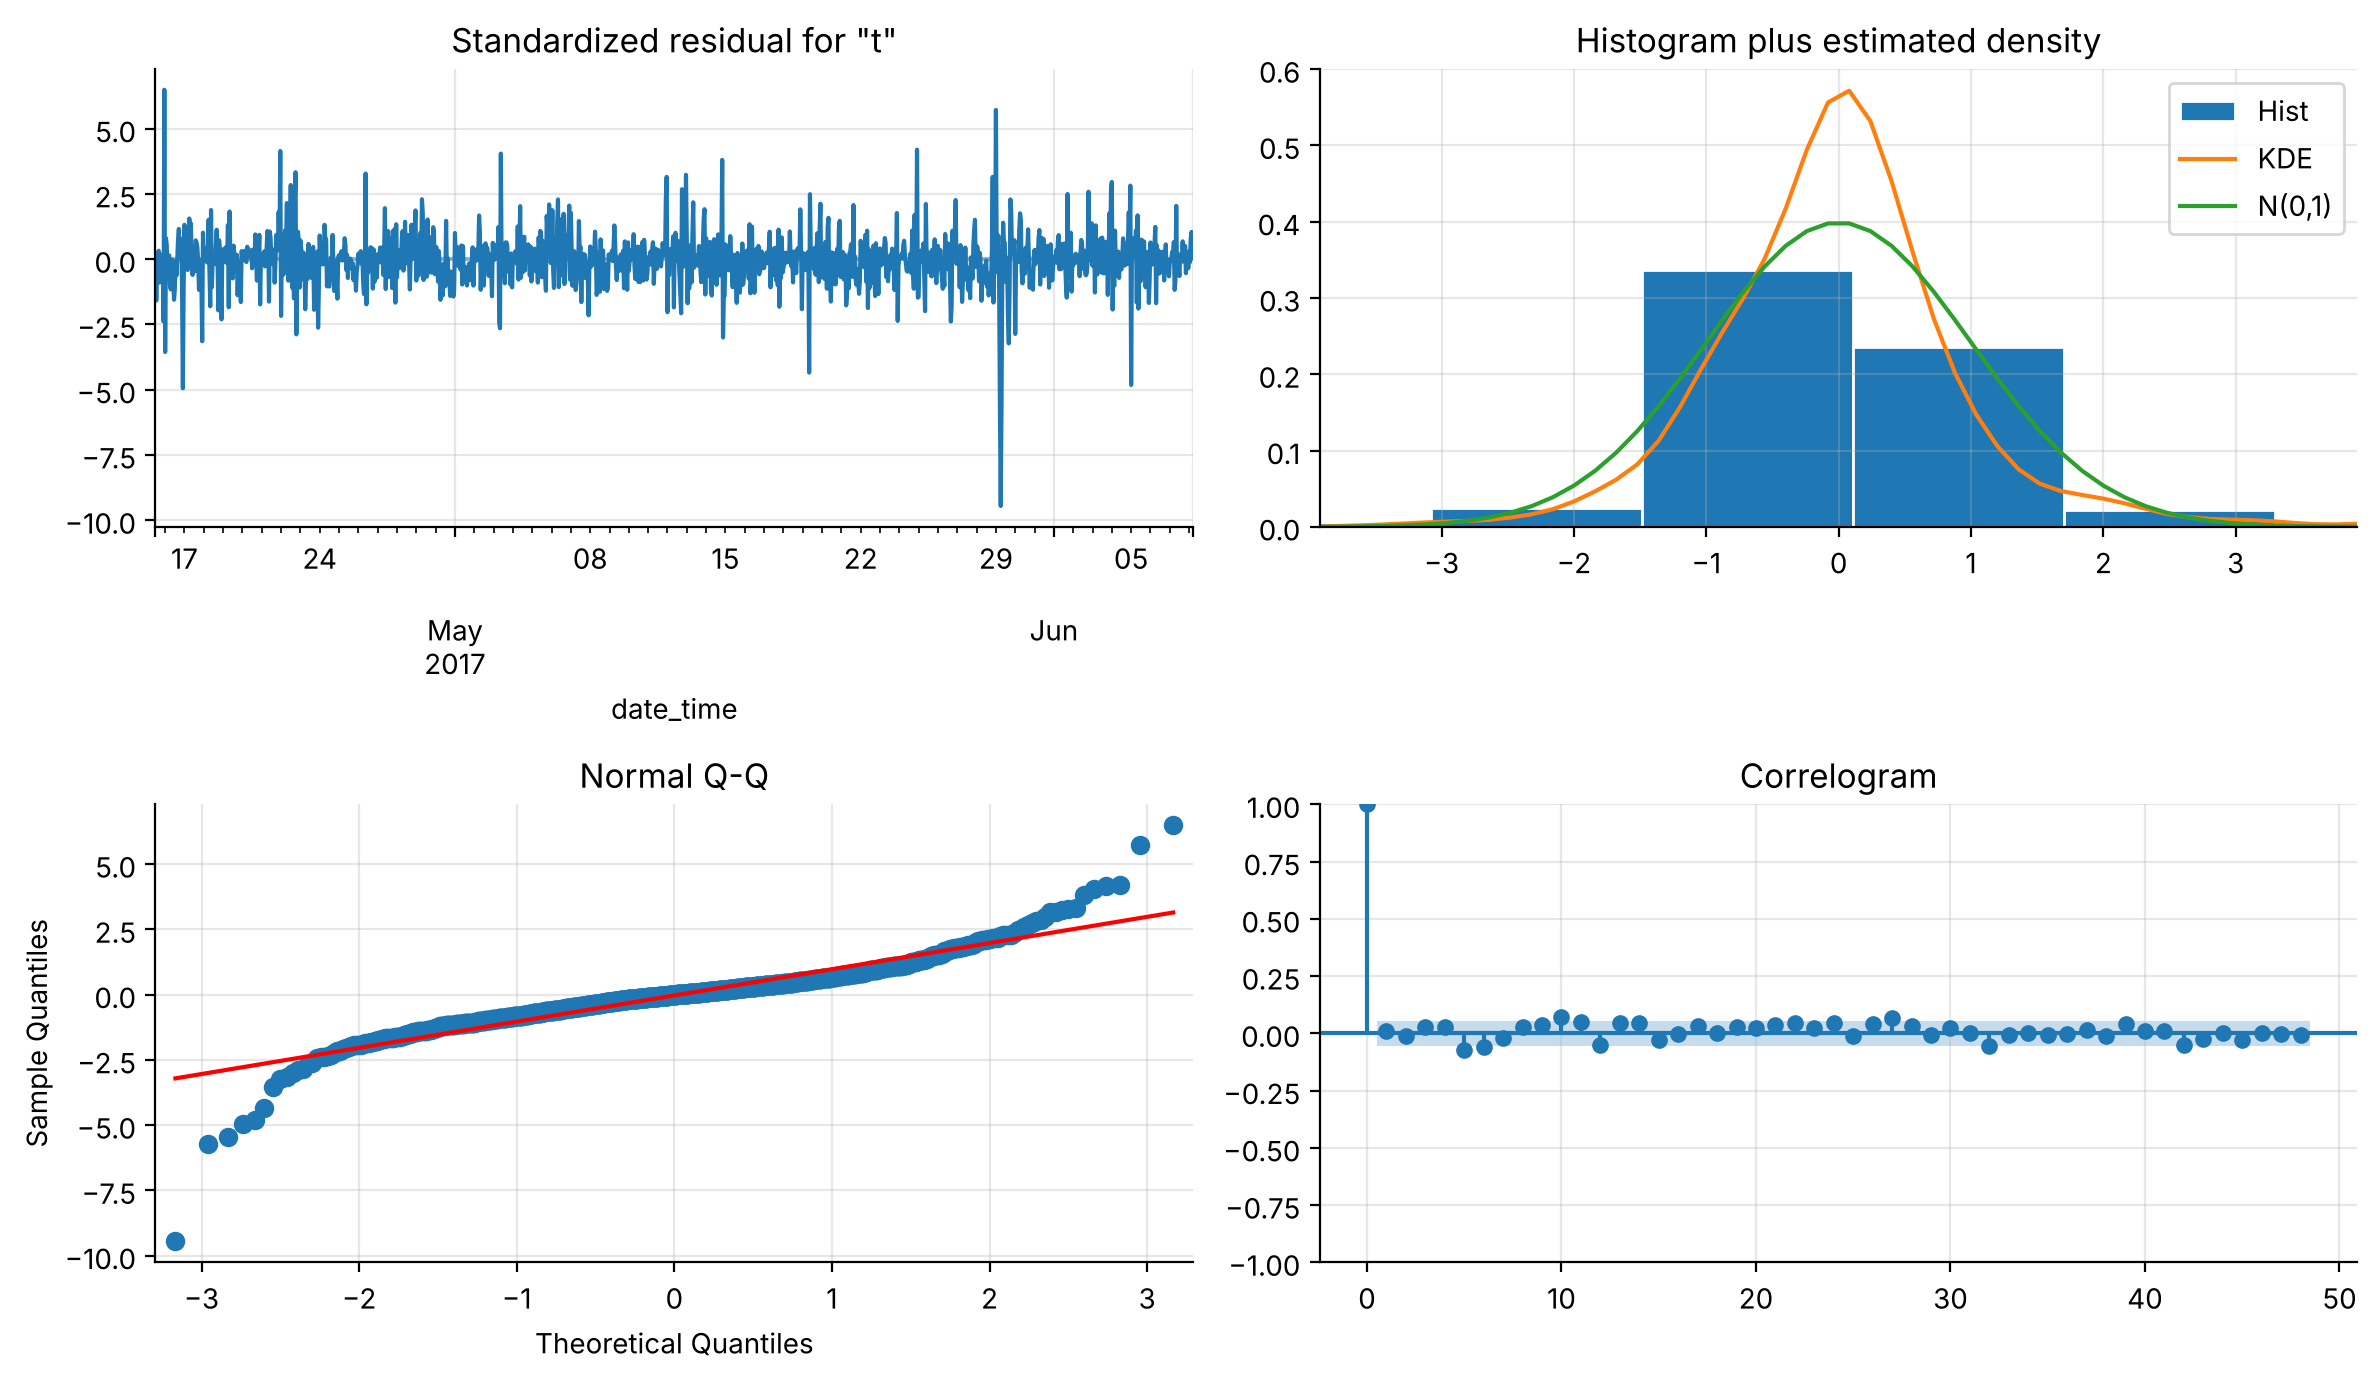

In [ ]:
fit_train = fit_sarimax(y_train, exog[calendar_cols].iloc[:n_train], best_order, best_seasonal)
print(fit_train.summary().tables[1])
fig = fit_train.plot_diagnostics(figsize=(12, 7), lags=48)
plt.tight_layout()
plt.show()

### Step 4 — Rolling 24-hour-ahead evaluation on the test part
For every origin `t` (every `sarimax_origin_step` hours) the model sees the series up to `t` and forecasts the next
24 hours. Parameters stay fixed; `apply` simply re-runs the Kalman filter over the longer history, which is cheap.
Holt-Winters is re-fitted at each origin (it is fast), so the classical baseline gets *more* adaptation than SARIMAX.

In [ ]:
def rolling_forecasts(fitted, y: pd.Series, x: pd.DataFrame | None, origins: range, horizon: int) -> np.ndarray:
    """Forecast `horizon` steps from every origin using only data before the origin. Shape: (n_origins, horizon)."""
    out = []
    for origin in origins:
        history_x = None if x is None else x.iloc[:origin]
        future_x = None if x is None else x.iloc[origin: origin + horizon]
        refreshed = fitted.apply(y.iloc[:origin], exog=history_x, refit=False)
        out.append(refreshed.forecast(horizon, exog=future_x).to_numpy())
    return np.vstack(out)


def holt_winters_forecasts(y: pd.Series, origins: range, horizon: int, season: int) -> np.ndarray:
    out = []
    for origin in origins:
        fitted = ExponentialSmoothing(y.iloc[:origin], trend=None, seasonal="add", seasonal_periods=season,
                                      initialization_method="estimated").fit()
        out.append(fitted.forecast(horizon).to_numpy())
    return np.vstack(out)


origins = range(n_val_end, n_stretch - cfg.horizon + 1, cfg.sarimax_origin_step)
horizon_steps = np.arange(cfg.horizon)
y_values = y_stretch.to_numpy()

# Re-estimate on train + validation, then freeze the parameters.
variants = {                                   # name -> exogenous columns (None = plain SARIMA)
    "SARIMA (no exog)": None,
    "SARIMAX (calendar)": calendar_cols,
    "SARIMAX (calendar + weather)": list(exog.columns),
}
forecasts = {}
for name, columns in variants.items():
    x = None if columns is None else exog[columns]
    fitted = fit_sarimax(y_stretch.iloc[:n_val_end], None if x is None else x.iloc[:n_val_end], best_order, best_seasonal)
    forecasts[name] = rolling_forecasts(fitted, y_stretch, x, origins, cfg.horizon)
forecasts["Holt-Winters (additive, s=24)"] = holt_winters_forecasts(y_stretch, origins, cfg.horizon, cfg.season_length)

# Targets and baselines on the very same (origin, step) grid.
target_index = np.array(origins)[:, None] + horizon_steps                 # (n_origins, 24)
y_true_sarimax = y_values[target_index]
SARIMAX_SET = "Test windows: longest gap-free stretch (24 h)"

tracker.add_baselines(
    SARIMAX_SET, horizon="24 h", y_true=y_true_sarimax,
    baseline_preds={SEASONAL_NAIVE: y_values[target_index - 168],
                    "Last-day naive (t-24)": y_values[target_index - 24]})

notes = {"SARIMA (no exog)": "no exogenous inputs; blind to the weekly cycle",
         "SARIMAX (calendar)": "weekend + holiday flags (known in advance)",
         "SARIMAX (calendar + weather)": "uses actual future weather (perfect-forecast upper bound)",
         "Holt-Winters (additive, s=24)": "statistical baseline, refitted every origin"}
for name, prediction in forecasts.items():
    row = tracker.add(name, SARIMAX_SET, "24 h", y_true_sarimax, prediction, note=notes[name])
    print(f"{name:32s} MAE={row['MAE']:7.1f}  RMSE={row['RMSE']:7.1f}  sMAPE={row['sMAPE']:5.2f}%  ({len(origins)} origins)")

SARIMA (no exog)                 MAE=  462.3  RMSE=  725.0  sMAPE=17.07%  (45 origins)
SARIMAX (calendar)               MAE=  218.4  RMSE=  305.0  sMAPE= 9.84%  (45 origins)
SARIMAX (calendar + weather)     MAE=  224.3  RMSE=  311.3  sMAPE=10.58%  (45 origins)
Holt-Winters (additive, s=24)    MAE=  693.9  RMSE=  943.9  sMAPE=30.50%  (45 origins)


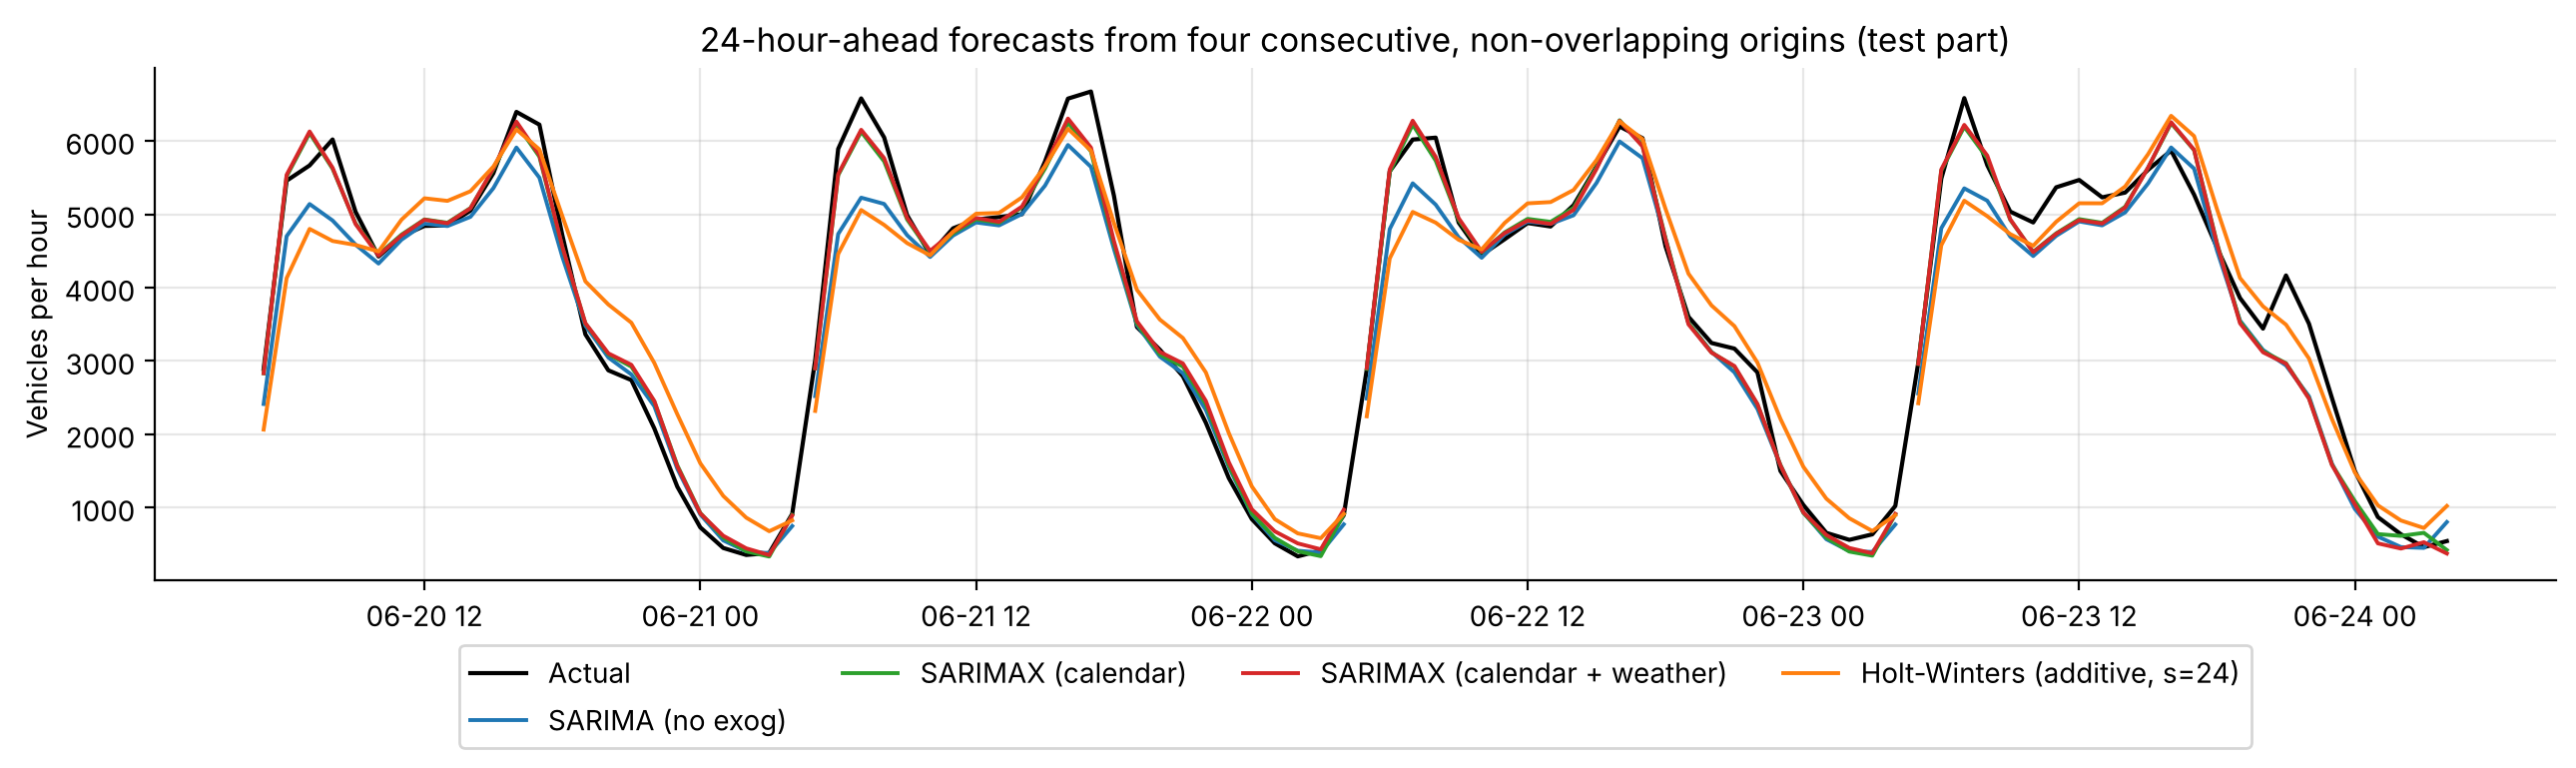

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
show_origins = list(range(0, 16, 4))      # four consecutive, non-overlapping days
first, last = origins[show_origins[0]], origins[show_origins[-1]] + cfg.horizon
ax.plot(y_stretch.index[first:last], y_values[first:last], color="black", lw=1.5, label="Actual")
for (name, prediction), color in zip(forecasts.items(), ["tab:blue", "tab:green", "tab:red", "tab:orange"]):
    for j, i in enumerate(show_origins):
        window = y_stretch.index[origins[i]: origins[i] + cfg.horizon]
        ax.plot(window, prediction[i], color=color, lw=1.4, label=name if j == 0 else None)
ax.set(title="24-hour-ahead forecasts from four consecutive, non-overlapping origins (test part)",
       ylabel="Vehicles per hour")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

**Reading the results.** Compare the rows in this order: *SARIMA → SARIMAX (calendar)* shows how much the weekly
structure matters when the seasonal period is only 24; *SARIMAX (calendar) → (calendar + weather)* shows the
extra value of weather. In this particular stretch (spring / early summer, no rain or snow recorded) weather has
little to explain, so do not generalise that gap to winter — it is a direct consequence of having a single long
gap-free period to fit on.

## 9. Shared data pipeline for the neural models (LSTM, GRU, PatchTST)

Both deep models read the same thing: **the past 168 hours** of traffic, weather and time encodings, and output
the **next 24 hours** of traffic in one shot (direct multi-step forecasting, no error accumulation from feeding
predictions back in).

Decisions that matter for correctness:
* **Windows never cross a gap.** A window is kept only if all 168 + 24 hours lie in one continuous segment.
* **No leakage across splits.** A window belongs to *train* only if its **last forecast hour** is inside the training
  period (likewise for validation). Its *inputs* may reach back into earlier periods — that is just history.
* **Scaling uses training statistics only.** Rain and snow are heavy-tailed, so they get `log1p` first.
* **Past weather only.** The inputs are observed up to the forecast origin; the model is not told the future weather.
* Train windows are sub-sampled with `train_stride` (neighbouring windows overlap by 191 of 192 hours, so little is lost).

In [ ]:
NN_FEATURES = ["traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all",
               "is_holiday", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]
STANDARDISE = ["traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all"]   # sin/cos and the 0/1 flag stay as they are
LOG_TRANSFORM = ["rain_1h", "snow_1h"]


class FeatureScaler:
    """log1p on heavy-tailed columns, then z-score with statistics fitted on the training data only."""

    def __init__(self, columns: list[str], standardise: list[str], log_transform: list[str]) -> None:
        self.columns, self.standardise, self.log_transform = columns, standardise, log_transform

    def _prepare(self, frame: pd.DataFrame) -> pd.DataFrame:
        values = frame[self.columns].astype(float)
        values[self.log_transform] = np.log1p(values[self.log_transform])
        return values

    def fit(self, frame: pd.DataFrame) -> "FeatureScaler":
        values = self._prepare(frame)
        self.mean_ = pd.Series(0.0, index=self.columns)
        self.std_ = pd.Series(1.0, index=self.columns)
        self.mean_[self.standardise] = values[self.standardise].mean()
        self.std_[self.standardise] = values[self.standardise].std()
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        return ((self._prepare(frame) - self.mean_) / self.std_).to_numpy(dtype=np.float32)

    def inverse_traffic(self, scaled: np.ndarray) -> np.ndarray:
        return scaled * self.std_["traffic_volume"] + self.mean_["traffic_volume"]


train_hours = hourly[(hourly["split"] == "train") & hourly["valid"]]
scaler = FeatureScaler(NN_FEATURES, STANDARDISE, LOG_TRANSFORM).fit(train_hours)

features = np.nan_to_num(scaler.transform(hourly))        # NaN only sits in unusable hours, never inside a window
scaled_traffic = features[:, NN_FEATURES.index("traffic_volume")]
raw_traffic = hourly["traffic_volume"].to_numpy()          # original units, for metrics and baselines
observed = hourly["observed"].to_numpy()
print(f"feature matrix {features.shape}, scaled traffic mean/std on train: "
      f"{scaled_traffic[hourly['split'].eq('train').to_numpy() & hourly['valid'].to_numpy()].mean():.2f} / "
      f"{scaled_traffic[hourly['split'].eq('train').to_numpy() & hourly['valid'].to_numpy()].std():.2f}")

feature matrix (52551, 10), scaled traffic mean/std on train: -0.00 / 1.00


In [ ]:
@dataclass(frozen=True)
class WindowStarts:
    """Index of the first input hour of every window, per split."""
    train: np.ndarray
    val: np.ndarray
    test: np.ndarray


def make_window_starts(hourly: pd.DataFrame, cfg: Config, bounds: SplitBoundaries) -> WindowStarts:
    segment = hourly["segment_id"].to_numpy()
    window_len = cfg.input_len + cfg.horizon
    starts = np.arange(len(hourly) - window_len + 1)
    starts = starts[(segment[starts] >= 0) & (segment[starts] == segment[starts + window_len - 1])]

    first_target, last_target = starts + cfg.input_len, starts + window_len - 1
    train_end = hourly.index.get_loc(bounds.train_end)
    val_end = hourly.index.get_loc(bounds.val_end)
    return WindowStarts(train=starts[last_target <= train_end][:: cfg.train_stride],
                        val=starts[(first_target > train_end) & (last_target <= val_end)],
                        test=starts[first_target > val_end])


window_starts = make_window_starts(hourly, cfg, bounds)
print({name: len(getattr(window_starts, name)) for name in ("train", "val", "test")}, "windows")

{'train': 11699, 'val': 6095, 'test': 6287} windows


In [ ]:
def make_dataset(starts: np.ndarray, cfg: Config, shuffle: bool) -> tf.data.Dataset:
    """Lazily slice (past 168 h of features, next 24 h of scaled traffic) out of the full arrays.

    Gathering inside `tf.data` means we never materialise the ~35,000 x 168 x 10 tensor of overlapping windows.
    """
    features_tf = tf.constant(features)
    target_tf = tf.constant(scaled_traffic)
    input_offsets = tf.range(cfg.input_len)
    target_offsets = tf.range(cfg.input_len, cfg.input_len + cfg.horizon)

    def gather_window(start):
        return (tf.gather(features_tf, start + input_offsets),
                tf.gather(target_tf, start + target_offsets))

    dataset = tf.data.Dataset.from_tensor_slices(starts.astype("int32"))
    if shuffle:
        dataset = dataset.shuffle(len(starts), seed=cfg.seed, reshuffle_each_iteration=True)
    return (dataset.map(gather_window, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(cfg.batch_size).prefetch(tf.data.AUTOTUNE))


train_ds = make_dataset(window_starts.train, cfg, shuffle=True)
val_ds = make_dataset(window_starts.val, cfg, shuffle=False)
test_ds = make_dataset(window_starts.test, cfg, shuffle=False)

for x_batch, y_batch in train_ds.take(1):
    print("input batch :", x_batch.shape, "(batch, past hours, features)")
    print("target batch:", y_batch.shape, "(batch, future hours)")

input batch : (128, 168, 10) (batch, past hours, features)
target batch: (128, 24) (batch, future hours)


In [ ]:
def gather_from(array: np.ndarray, starts: np.ndarray, offset: int, length: int) -> np.ndarray:
    """array[start + offset : start + offset + length] for every window start, as a (n_windows, length) matrix."""
    return array[starts[:, None] + offset + np.arange(length)]


assert cfg.input_len >= 168 and cfg.horizon <= 24, "the naive baselines below need a week of history and h <= 24"

WINDOW_SET = "Test windows: all segments (24 h)"
y_true_windows = gather_from(raw_traffic, window_starts.test, cfg.input_len, cfg.horizon)
window_mask = gather_from(observed, window_starts.test, cfg.input_len, cfg.horizon)

# Naive baselines read straight from the input window: step h of the forecast copies the hour 168 / 24 hours earlier.
tracker.add_baselines(
    WINDOW_SET, horizon="24 h", y_true=y_true_windows, mask=window_mask,
    baseline_preds={SEASONAL_NAIVE: gather_from(raw_traffic, window_starts.test, cfg.input_len - 168, cfg.horizon),
                    "Last-day naive (t-24)": gather_from(raw_traffic, window_starts.test, cfg.input_len - 24, cfg.horizon)})
print(f"{len(y_true_windows):,} test windows, {window_mask.sum():,} observed target hours")
tracker.table().query("test_set == @WINDOW_SET")[["model", "MAE", "RMSE", "sMAPE"]]

6,287 test windows, 150,600 observed target hours


,model,MAE,RMSE,sMAPE
7,Seasonal naive (t-168),338.949734,651.429364,12.366513
8,Last-day naive (t-24),561.146315,1025.994334,21.373386


In [ ]:
neural_predictions: dict[str, np.ndarray] = {}      # model name -> (n_test_windows, 24) in vehicles / hour
training_histories: dict[str, keras.callbacks.History] = {}


def train_and_evaluate(name: str, model: keras.Model, optimizer: keras.optimizers.Optimizer, note: str) -> dict:
    """Compile, fit with early stopping on the validation loss, then score on the test windows."""
    model.compile(optimizer=optimizer, loss=keras.losses.Huber(delta=1.0), metrics=["mae"])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=cfg.patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, cfg.patience // 2), min_lr=1e-5),
    ]
    training_histories[name] = model.fit(train_ds, validation_data=val_ds, epochs=cfg.epochs,
                                         callbacks=callbacks, verbose=2)
    prediction = scaler.inverse_traffic(model.predict(test_ds, verbose=0))
    neural_predictions[name] = prediction
    row = tracker.add(name, WINDOW_SET, "24 h", y_true_windows, prediction, mask=window_mask, note=note)
    print(f"\n{name}: test MAE={row['MAE']:.1f}  RMSE={row['RMSE']:.1f}  sMAPE={row['sMAPE']:.2f}%")
    return row


def plot_training_curves(names: list[str]) -> None:
    fig, axes = plt.subplots(1, len(names), figsize=(6 * len(names), 3.6), squeeze=False)
    for ax, name in zip(axes[0], names):
        history = training_histories[name].history
        ax.plot(history["loss"], label="train")
        ax.plot(history["val_loss"], label="validation")
        ax.set(title=f"{name}: Huber loss (scaled units)", xlabel="epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()

## 10. Model 4 — Deep learning: LSTM (with GRU as the alternative)

**Idea.** A recurrent network reads the 168 hourly steps in order and keeps a *memory* of what it has seen. The LSTM
has gates that decide what to remember and what to forget, which lets it carry "it is Tuesday morning and traffic has been
building for two hours" across many steps. The last hidden state is a summary of the week, and a small dense head maps it
to the 24 future values.

**Design**
* One recurrent layer (64 units) → dropout → dense(64, ReLU) → dense(24).
* Huber loss on standardised traffic: behaves like MSE for small errors and like MAE for large ones, so a few
  odd hours cannot dominate the gradient.
* Adam with learning-rate reduction on plateau; early stopping restores the best validation weights.
* The GRU is the same network with a GRU cell: fewer parameters, usually very similar accuracy.

In [ ]:
def build_recurrent_model(cell: str, cfg: Config, n_features: int, units: int = 64) -> keras.Model:
    """Past week of features -> next 24 hours of (scaled) traffic."""
    recurrent_layer = {"lstm": keras.layers.LSTM, "gru": keras.layers.GRU}[cell]
    inputs = keras.Input(shape=(cfg.input_len, n_features), name="past_week")
    x = recurrent_layer(units, name=cell)(inputs)
    x = keras.layers.Dropout(cfg.dropout)(x)
    x = keras.layers.Dense(64, activation="relu")(x)
    outputs = keras.layers.Dense(cfg.horizon, name="next_24h")(x)
    return keras.Model(inputs, outputs, name=f"{cell}_forecaster")


keras.utils.set_random_seed(cfg.seed)
lstm_model = build_recurrent_model("lstm", cfg, len(NN_FEATURES))
lstm_model.summary()

Model: "lstm_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ past_week (InputLayer)          │ (None, 168, 10)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_24h (Dense)                │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,920 (97.34 KB)

 Trainable params: 24,920 (97.34 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
train_and_evaluate("LSTM", lstm_model, keras.optimizers.Adam(1e-3, clipnorm=1.0),
                   note="past weather only, 168 h input -> 24 h")

Epoch 1/40


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 - 8s - 83ms/step - loss: 0.2236 - mae: 0.5307 - val_loss: 0.0877 - val_mae: 0.3061 - learning_rate: 0.0010


Epoch 2/40


92/92 - 10s - 108ms/step - loss: 0.0824 - mae: 0.3069 - val_loss: 0.0480 - val_mae: 0.2227 - learning_rate: 0.0010


Epoch 3/40


... (61 outputs left out)

Epoch 34/40


92/92 - 6s - 64ms/step - loss: 0.0279 - mae: 0.1683 - val_loss: 0.0206 - val_mae: 0.1311 - learning_rate: 1.2500e-04



LSTM: test MAE=261.8  RMSE=421.9  sMAPE=11.73%


{'model': 'LSTM',
 'test_set': 'Test windows: all segments (24 h)',
 'horizon': '24 h',
 'note': 'past weather only, 168 h input -> 24 h',
 'n_targets': 150600,
 'MAE': 261.81791844386777,
 'RMSE': 421.90622224774876,
 'sMAPE': 11.734166325433106}

Epoch 1/40


92/92 - 9s - 102ms/step - loss: 0.2279 - mae: 0.5377 - val_loss: 0.0948 - val_mae: 0.3211 - learning_rate: 0.0010


Epoch 2/40


92/92 - 7s - 81ms/step - loss: 0.0967 - mae: 0.3331 - val_loss: 0.0620 - val_mae: 0.2574 - learning_rate: 0.0010


Epoch 3/40


92/92 - 8s - 83ms/step - loss: 0.0701 - mae: 0.2816 - val_loss: 0.0425 - val_mae: 0.2098 - learning_rate: 0.0010


... (71 outputs left out)

92/92 - 8s - 91ms/step - loss: 0.0307 - mae: 0.1740 - val_loss: 0.0210 - val_mae: 0.1305 - learning_rate: 3.1250e-05


Epoch 40/40


92/92 - 8s - 84ms/step - loss: 0.0309 - mae: 0.1743 - val_loss: 0.0209 - val_mae: 0.1303 - learning_rate: 3.1250e-05



GRU: test MAE=260.5  RMSE=418.9  sMAPE=11.72%


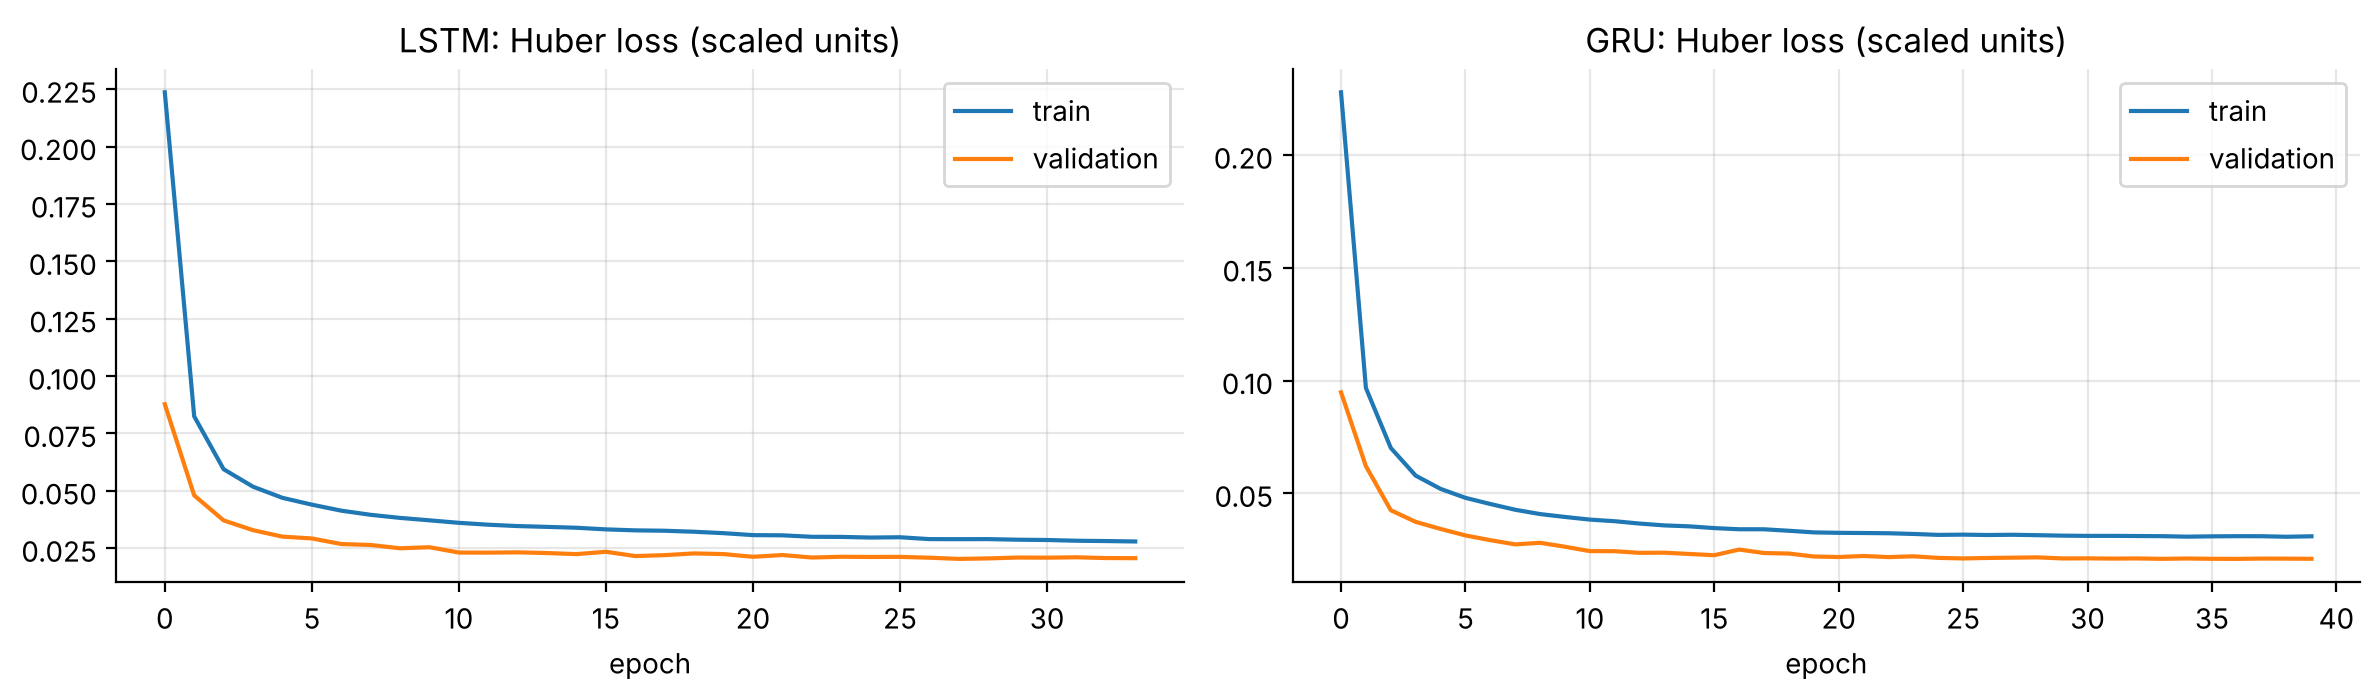

In [ ]:
if cfg.run_gru:
    keras.utils.set_random_seed(cfg.seed)
    gru_model = build_recurrent_model("gru", cfg, len(NN_FEATURES))
    train_and_evaluate("GRU", gru_model, keras.optimizers.Adam(1e-3, clipnorm=1.0),
                       note="past weather only, 168 h input -> 24 h")
plot_training_curves([n for n in ("LSTM", "GRU") if n in training_histories])

## 11. Model 5 — Transformer: PatchTST

**Idea.** Applying self-attention to every single hour is wasteful and noisy: one hour carries little meaning on
its own. PatchTST ([Nie et al., ICLR 2023](https://arxiv.org/abs/2211.14730)) makes two moves:

1. **Patching.** Cut each series into short overlapping *patches* (here 16 hours, stride 8 → 20 patches for a week).
   A patch is a "word": a local shape such as a morning ramp-up. Attention now runs over 20 tokens instead of 168, which
   is cheaper and lets each token represent a meaningful local pattern.
2. **Channel independence.** Every input channel (traffic, temperature, hour-of-day sine, …) is patched and encoded
   *separately* by the **same** shared Transformer encoder; the channels are only combined in the final
   prediction head. This regularises the model and works well in practice.

**Pipeline (shapes for a batch of B windows, C = 10 channels, N = 20 patches, d = 32)**

```
(B, 168, C) → transpose & merge channels into the batch → (B·C, 168)
            → patching            → (B·C, N, 16)
            → linear projection + learned position embedding → (B·C, N, d)
            → L × [LayerNorm → multi-head self-attention → residual → LayerNorm → feed-forward → residual]
            → flatten all channels' tokens → (B, C·N·d) → dense → (B, 24)
```

Adaptations to this project: the head reads *all* channels (so weather and calendar information reaches the traffic
forecast), and we skip the paper's reversible instance normalisation because the inputs are already standardised
with training statistics. The Keras layers are written out below so each step of the diagram is visible.

In [ ]:
class PatchEmbedding(keras.layers.Layer):
    """Cut each series into overlapping patches and map every patch to a `d_model` vector."""

    def __init__(self, input_len: int, patch_len: int, stride: int, d_model: int, **kwargs) -> None:
        super().__init__(**kwargs)
        self.patch_len, self.stride, self.d_model = patch_len, stride, d_model
        self.n_patches = (input_len - patch_len) // stride + 1
        self.projection = keras.layers.Dense(d_model, name="patch_projection")

    def build(self, input_shape) -> None:
        self.position = self.add_weight(name="position_embedding", shape=(self.n_patches, self.d_model),
                                        initializer=keras.initializers.RandomNormal(stddev=0.02))
        self.projection.build((None, self.n_patches, self.patch_len))

    def call(self, series):                                   # series: (batch*channels, input_len)
        patches = keras.ops.stack(
            [series[:, i * self.stride: i * self.stride + self.patch_len] for i in range(self.n_patches)], axis=1)
        return self.projection(patches) + self.position       # (batch*channels, n_patches, d_model)


class TransformerEncoderBlock(keras.layers.Layer):
    """Pre-norm Transformer encoder block: attention and feed-forward, each wrapped in a residual connection."""

    def __init__(self, d_model: int, n_heads: int, ff_dim: int, dropout: float, **kwargs) -> None:
        super().__init__(**kwargs)
        self.norm_attention = keras.layers.LayerNormalization(epsilon=1e-6)
        self.attention = keras.layers.MultiHeadAttention(num_heads=n_heads, key_dim=d_model // n_heads, dropout=dropout)
        self.norm_ff = keras.layers.LayerNormalization(epsilon=1e-6)
        self.feed_forward = keras.Sequential([keras.layers.Dense(ff_dim, activation="gelu"),
                                              keras.layers.Dropout(dropout),
                                              keras.layers.Dense(d_model)])
        self.dropout = keras.layers.Dropout(dropout)

    def call(self, tokens, training=False):
        normed = self.norm_attention(tokens)
        tokens = tokens + self.dropout(self.attention(normed, normed, training=training), training=training)
        return tokens + self.dropout(self.feed_forward(self.norm_ff(tokens), training=training), training=training)


class PatchTST(keras.Model):
    """Channel-independent patch Transformer with a flatten-and-project forecasting head."""

    def __init__(self, cfg: Config, n_channels: int, **kwargs) -> None:
        super().__init__(**kwargs)
        self.input_len, self.n_channels = cfg.input_len, n_channels
        self.patch_embedding = PatchEmbedding(cfg.input_len, cfg.patch_len, cfg.patch_stride, cfg.d_model)
        self.encoder_blocks = [TransformerEncoderBlock(cfg.d_model, cfg.n_heads, cfg.ff_dim, cfg.dropout)
                               for _ in range(cfg.n_layers)]
        self.final_norm = keras.layers.LayerNormalization(epsilon=1e-6)
        self.head_dropout = keras.layers.Dropout(cfg.dropout)
        self.head = keras.layers.Dense(cfg.horizon, name="next_24h")
        self.flat_size = n_channels * self.patch_embedding.n_patches * cfg.d_model

    def call(self, x, training=False):                        # x: (batch, input_len, channels)
        # Channel independence: every channel becomes its own univariate series inside the batch dimension.
        series = keras.ops.reshape(keras.ops.transpose(x, (0, 2, 1)), (-1, self.input_len))
        tokens = self.patch_embedding(series)
        for block in self.encoder_blocks:
            tokens = block(tokens, training=training)
        tokens = self.final_norm(tokens)
        per_window = keras.ops.reshape(tokens, (-1, self.flat_size))        # gather the channels back together
        return self.head(self.head_dropout(per_window, training=training))  # (batch, horizon)


keras.utils.set_random_seed(cfg.seed)
patchtst_model = PatchTST(cfg, n_channels=len(NN_FEATURES), name="patchtst")
patchtst_model(tf.zeros((1, cfg.input_len, len(NN_FEATURES))))               # build the weights so summary() works
patchtst_model.summary()
print(f"Patches per window: {patchtst_model.patch_embedding.n_patches} (length {cfg.patch_len}, stride {cfg.patch_stride})")

Model: "patchtst"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ patch_embedding                 │ ?                      │         1,184 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block       │ ?                      │         8,544 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block_1     │ ?                      │         8,544 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_4           │ (10, 20, 32)           │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_24h (Dense)                │ (1, 24)                │       153,624 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 171,960 (671.72 KB)

 Trainable params: 171,960 (671.72 KB)

 Non-trainable params: 0 (0.00 B)

Patches per window: 20 (length 16, stride 8)


Epoch 1/40


92/92 - 25s - 269ms/step - loss: 0.4217 - mae: 0.7883 - val_loss: 0.0887 - val_mae: 0.3335 - learning_rate: 0.0010


Epoch 2/40


92/92 - 18s - 196ms/step - loss: 0.1641 - mae: 0.4564 - val_loss: 0.0495 - val_mae: 0.2351 - learning_rate: 0.0010


Epoch 3/40


92/92 - 21s - 223ms/step - loss: 0.0805 - mae: 0.3090 - val_loss: 0.0381 - val_mae: 0.2003 - learning_rate: 0.0010


... (71 outputs left out)

92/92 - 17s - 186ms/step - loss: 0.0282 - mae: 0.1610 - val_loss: 0.0198 - val_mae: 0.1240 - learning_rate: 2.5000e-04


Epoch 40/40


92/92 - 20s - 221ms/step - loss: 0.0281 - mae: 0.1604 - val_loss: 0.0201 - val_mae: 0.1243 - learning_rate: 2.5000e-04



PatchTST: test MAE=256.6  RMSE=425.4  sMAPE=12.03%


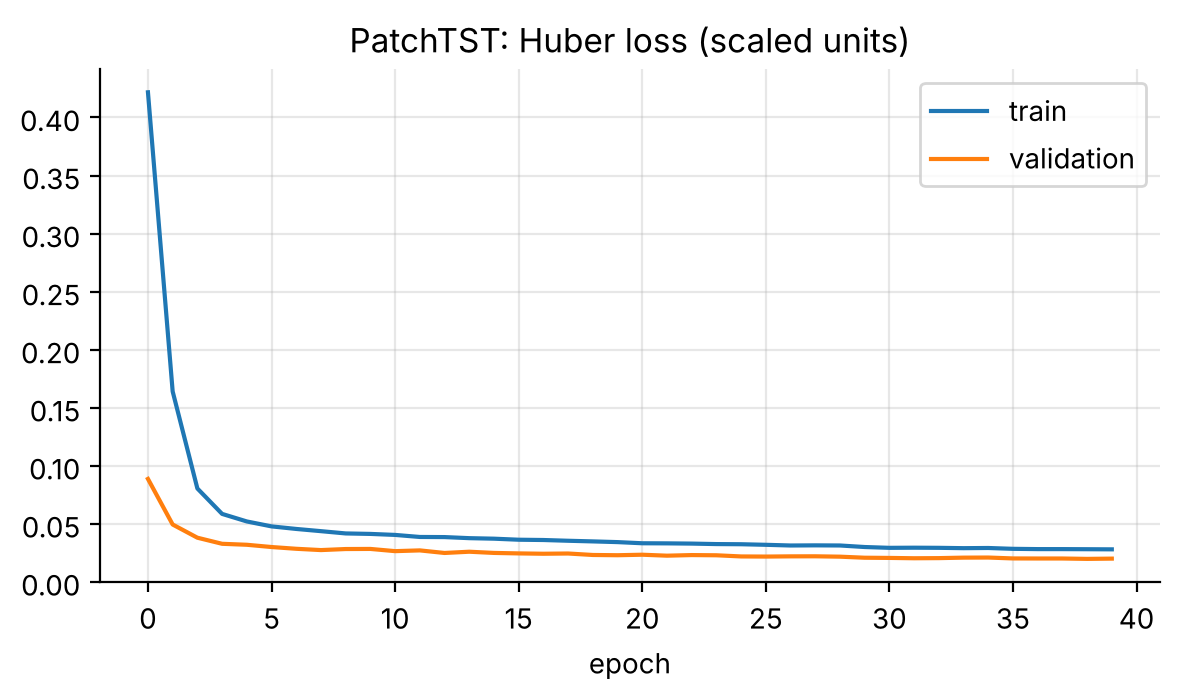

In [ ]:
train_and_evaluate("PatchTST", patchtst_model,
                   keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4, clipnorm=1.0),
                   note="past weather only, 168 h input -> 24 h")
plot_training_curves(["PatchTST"])

### How do the neural models behave across the forecast horizon?
Forecasting step 1 is easy (the last observed hour is almost the answer); step 24 must rely on the daily
pattern. A healthy model beats the seasonal-naive baseline at *every* step, and the gap is widest at the short end.

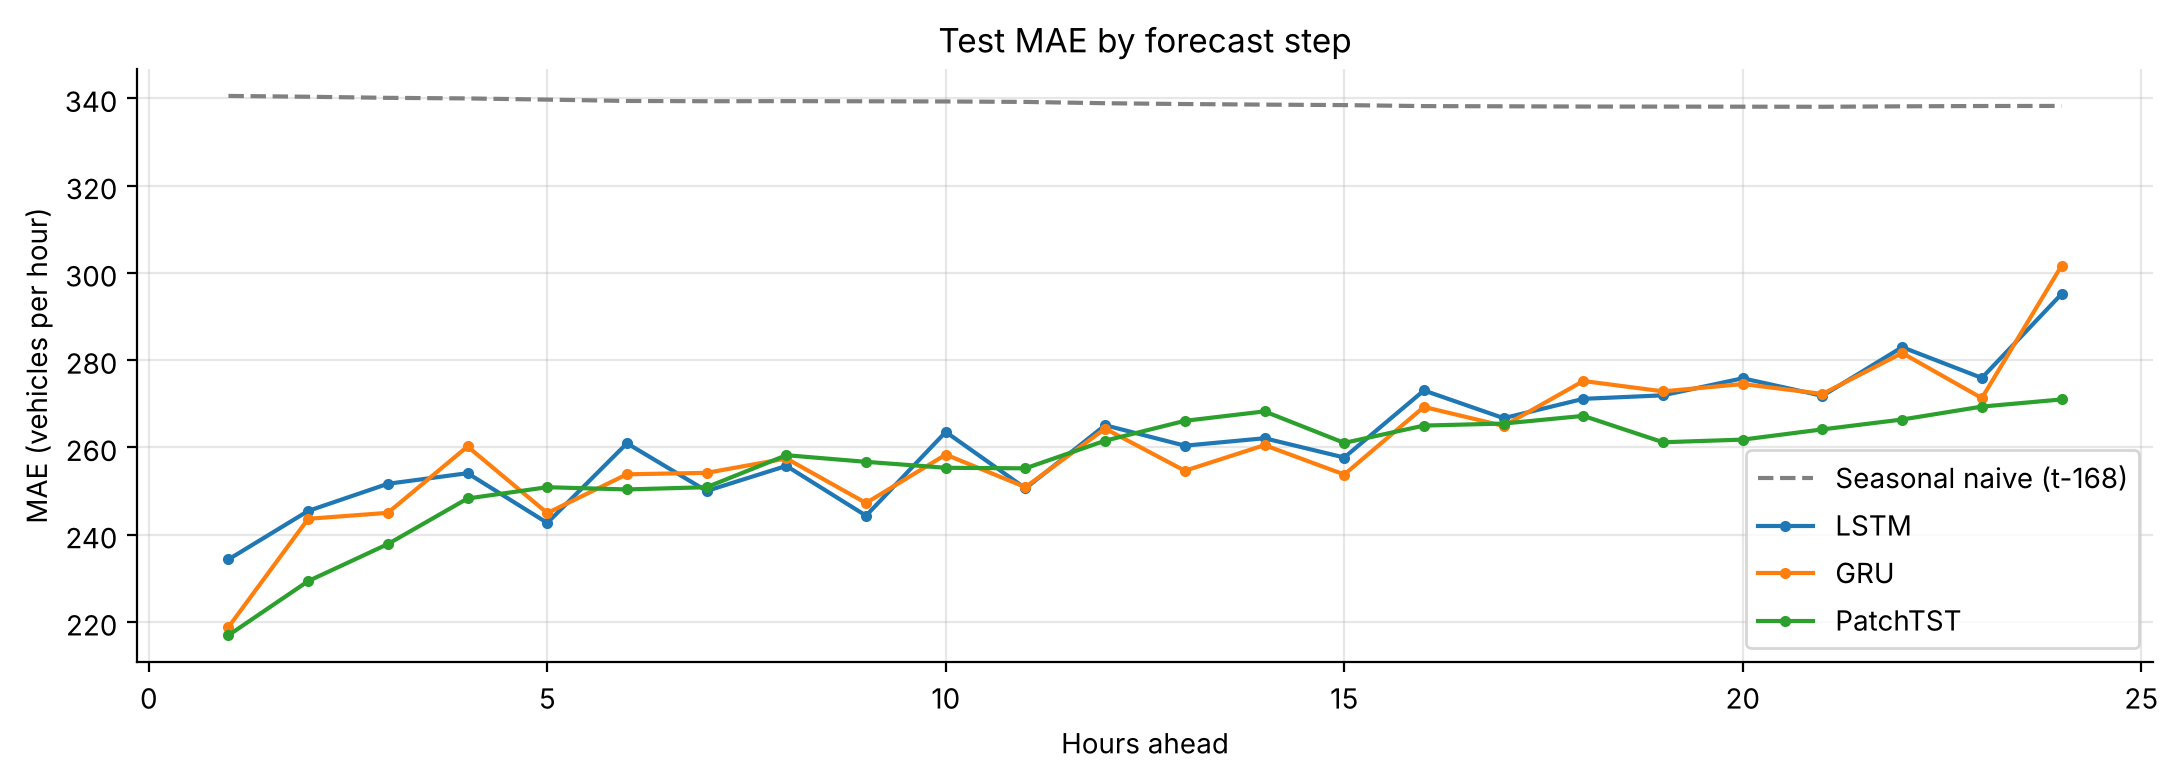

In [ ]:
horizon_axis = np.arange(1, cfg.horizon + 1)


def mae_per_step(y_true: np.ndarray, y_pred: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """MAE of each forecast step, ignoring interpolated targets."""
    errors = np.where(mask, np.abs(y_true - y_pred), np.nan)
    return np.nanmean(errors, axis=0)


seasonal_naive_windows = gather_from(raw_traffic, window_starts.test, cfg.input_len - 168, cfg.horizon)
fig, ax = plt.subplots()
ax.plot(horizon_axis, mae_per_step(y_true_windows, seasonal_naive_windows, window_mask),
        color="grey", ls="--", label=SEASONAL_NAIVE)
for name, prediction in neural_predictions.items():
    ax.plot(horizon_axis, mae_per_step(y_true_windows, prediction, window_mask), marker="o", ms=3, label=name)
ax.set(title="Test MAE by forecast step", xlabel="Hours ahead", ylabel="MAE (vehicles per hour)")
ax.legend()
plt.tight_layout()
plt.show()

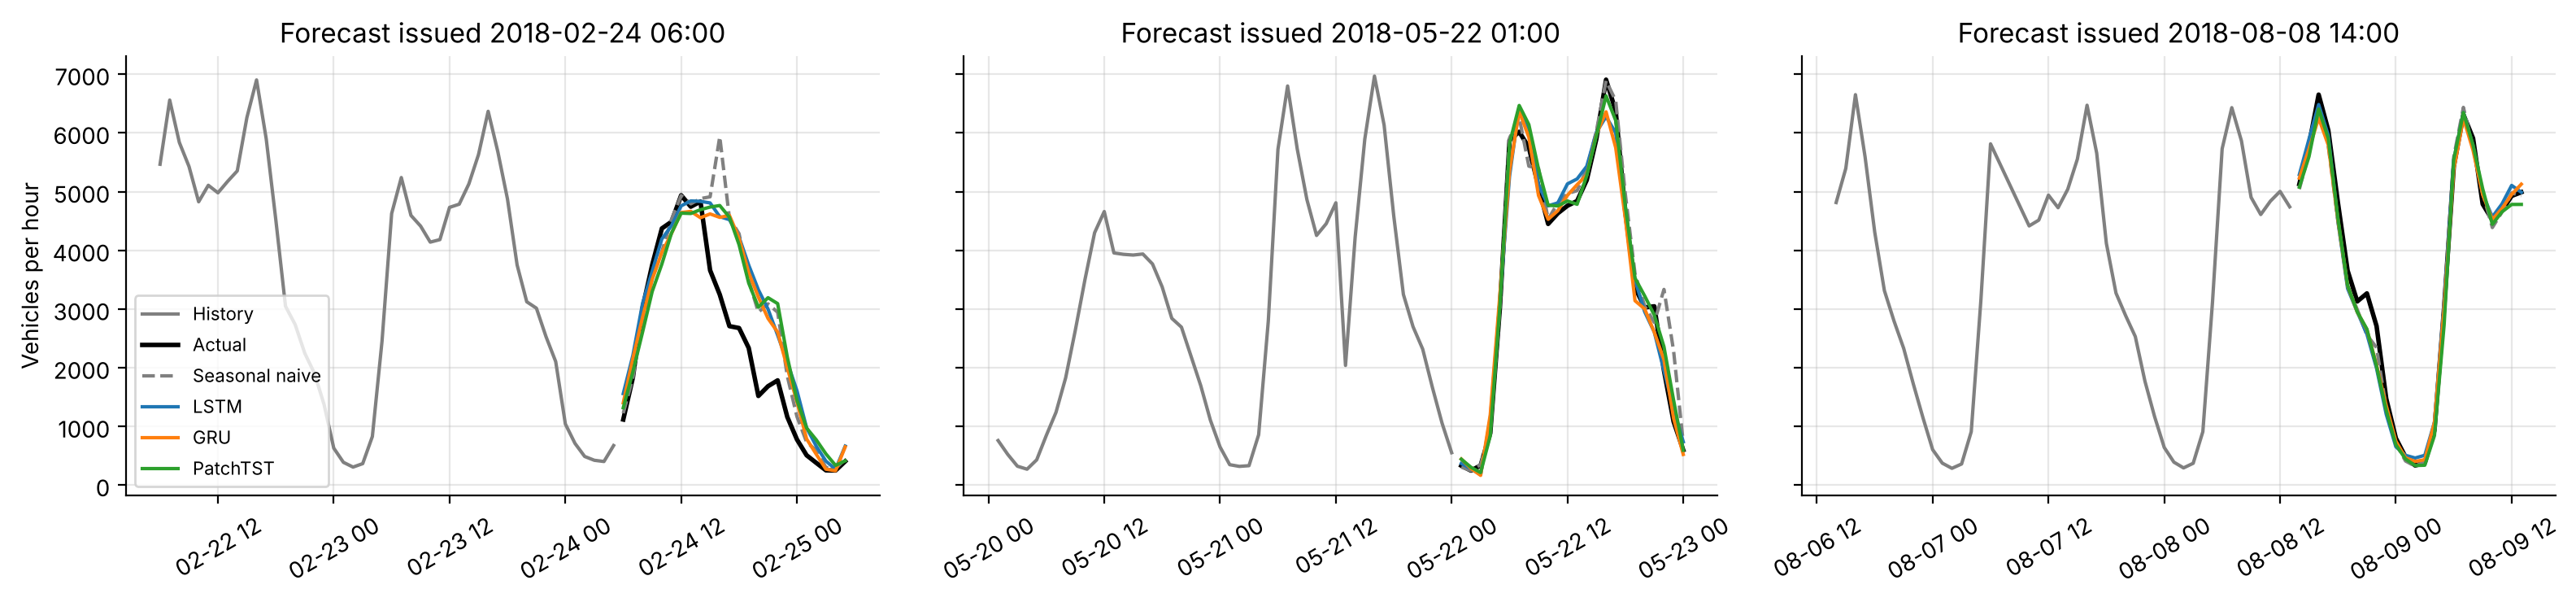

In [ ]:
# Three example forecasts from different parts of the test period (last 48 h of input, then the 24 h forecast).
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, position in zip(axes, np.quantile(np.arange(len(window_starts.test)), [0.2, 0.5, 0.8]).astype(int)):
    start = window_starts.test[position]
    origin = start + cfg.input_len
    ax.plot(hourly.index[origin - 48: origin], raw_traffic[origin - 48: origin], color="grey", label="History")
    ax.plot(hourly.index[origin: origin + cfg.horizon], y_true_windows[position], color="black", lw=2, label="Actual")
    ax.plot(hourly.index[origin: origin + cfg.horizon], seasonal_naive_windows[position], color="grey", ls="--", label="Seasonal naive")
    for name, prediction in neural_predictions.items():
        ax.plot(hourly.index[origin: origin + cfg.horizon], prediction[position], label=name)
    ax.set_title(f"Forecast issued {hourly.index[origin]:%Y-%m-%d %H:%M}")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Vehicles per hour")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 12. Final comparison
One table, one protocol. **Read it per `test_set`** — rows in different blocks are scored on different test targets
and must not be ranked against each other directly. What *is* comparable across blocks is the last column,
**skill**: the % reduction in MAE relative to the seasonal-naive baseline *on that block's own targets*.

| Test set | Used by | Targets |
|---|---|---|
| Test hours | LightGBM, Ridge | every observed test hour with a full week of history |
| Test windows: all segments | LSTM, GRU, PatchTST | 24-hour forecasts from every origin in the test period |
| Test windows: longest gap-free stretch | SARIMA / SARIMAX, Holt-Winters | 24-hour forecasts, origins every 6 h inside the Apr–Jul 2017 stretch |

K-Means is unsupervised and has no forecast error; its evidence is the cluster analysis in section 7.

In [ ]:
results = tracker.table()
results.to_csv(Path(cfg.output_dir) / "model_comparison.csv", index=False)

COLUMNS = ["model", "horizon", "MAE", "RMSE", "sMAPE", "skill_vs_seasonal_naive_%", "n_targets", "note"]
for test_set, block in results.groupby("test_set", sort=False):
    print(f"\n=== {test_set} ===")
    print(block[COLUMNS].round(1).to_string(index=False))


=== Test hours (single-step & day-ahead) ===
                  model horizon   MAE   RMSE  sMAPE  skill_vs_seasonal_naive_%  n_targets                                              note
   LightGBM [with_lags]     1 h 141.1  217.8    5.7                       58.4       6321 concurrent weather; lags 1,2,3,24,168 + 24 h mean
   LightGBM [day_ahead]    24 h 213.8  360.6    8.6                       37.0       6321             concurrent weather; lags >= 24 h only
     LightGBM [no_lags]     n/a 229.7  363.9   10.0                       32.4       6321      weather + calendar only (no traffic history)
Ridge (linear baseline)     1 h 237.0  339.3   11.5                       30.2       6321                 one-hot calendar + lags + weather
 Seasonal naive (t-168)     1 h 339.6  651.4   12.4                        0.0       6321                                          baseline
  Last-day naive (t-24)     1 h 562.1 1025.7   21.4                      -65.5       6321                         

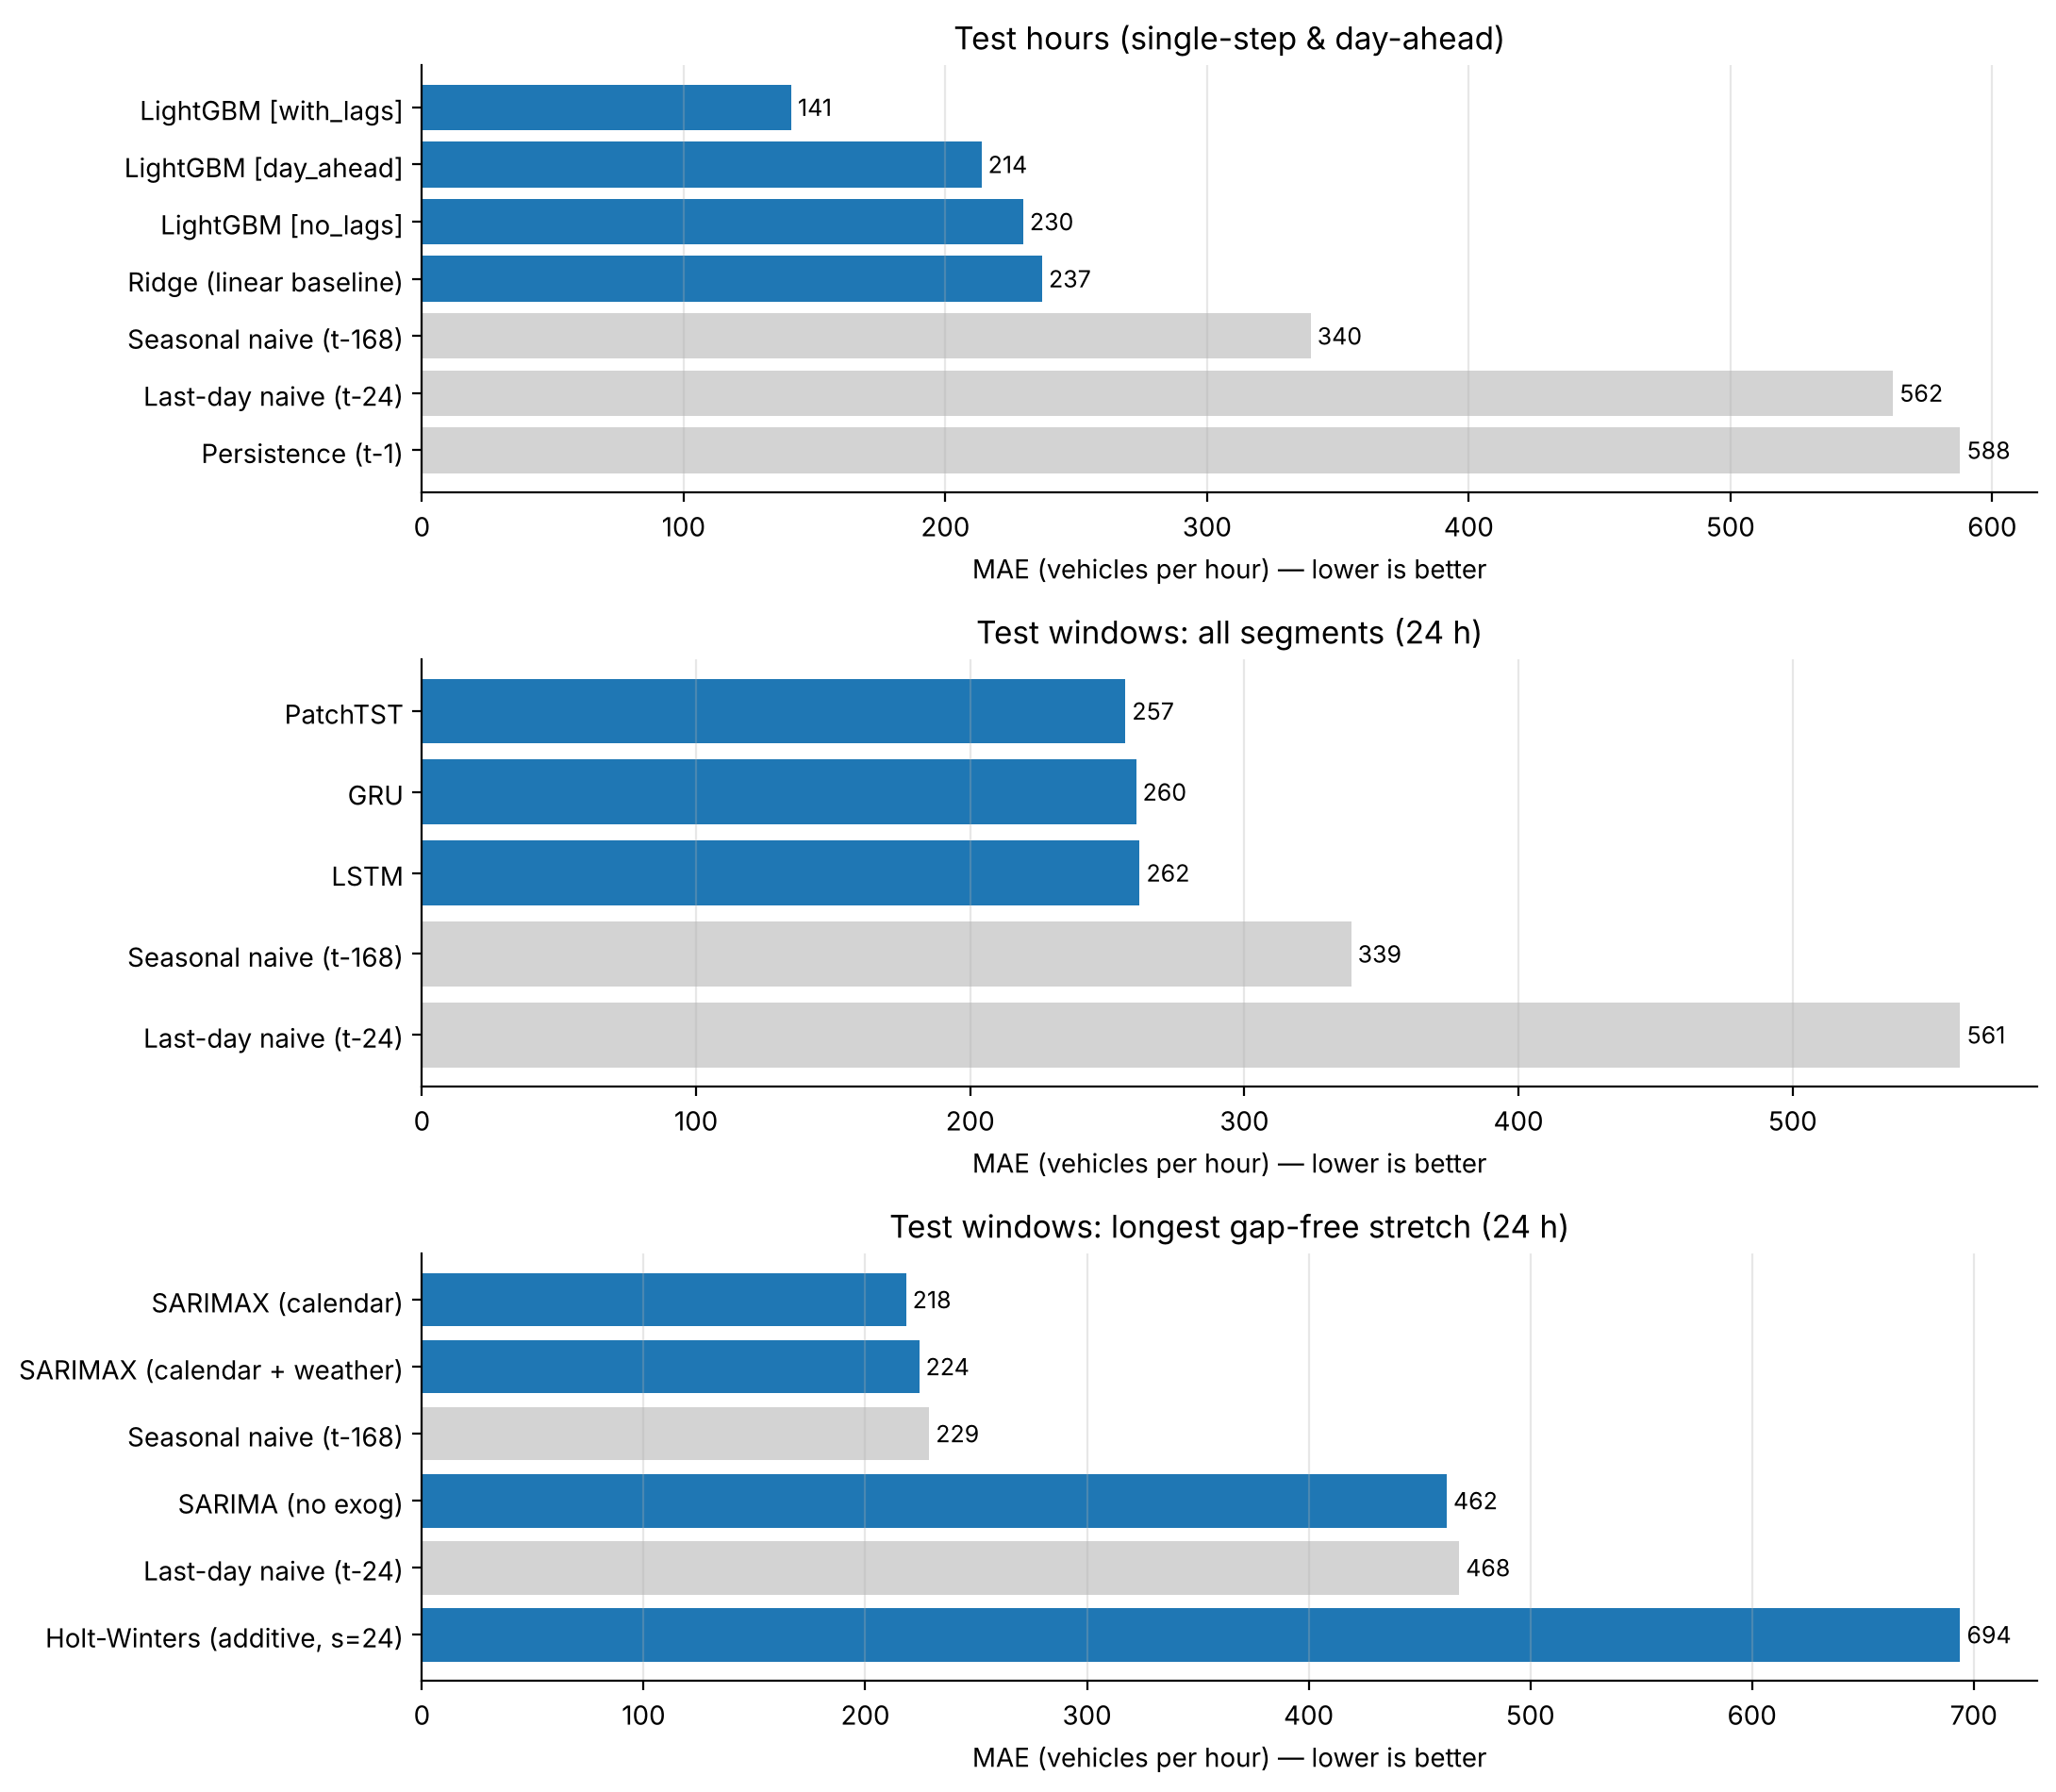

In [ ]:
test_sets = list(results["test_set"].unique())
fig, axes = plt.subplots(len(test_sets), 1, figsize=(11, 3.2 * len(test_sets)))
for ax, test_set in zip(np.atleast_1d(axes), test_sets):
    block = results[results["test_set"] == test_set].sort_values("MAE", ascending=False)
    colors = np.where(block["note"] == "baseline", "lightgrey", "tab:blue")
    ax.barh(block["model"], block["MAE"], color=colors)
    for y_pos, value in enumerate(block["MAE"]):
        ax.text(value, y_pos, f" {value:.0f}", va="center", fontsize=9)
    ax.set(title=test_set, xlabel="MAE (vehicles per hour) — lower is better")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## Takeaways

| Question | Answer from this run |
|---|---|
| Best 1-hour-ahead model | **LightGBM with lags**: MAE ≈ 141 vehicles/h, 58 % better than seasonal naive. Ridge on the same inputs (≈ 237) is no better than LightGBM *without* any lags (≈ 230): the hour × weekday × weather interactions matter and a linear model cannot express them. |
| How much does traffic history add? | A lot: calendar + weather alone (`no_lags`) already beats the naive baselines by ~32 %, but adding the previous hours takes it to 58 %. |
| Do clusters mean anything? | Yes — weekday / Saturday / Sunday-and-holiday, recovered without being told the calendar. |
| SARIMAX | With `s = 24` only, it cannot see the weekly cycle and is as bad as last-day naive. With weekend × hour harmonics it reaches MAE ≈ 218, only ~5 % better than seasonal naive. Weather did **not** help in this dry spring/summer stretch. Holt-Winters (s = 24) is weakest for the same weekly-blindness reason. |
| LSTM vs GRU vs PatchTST | All three are ≈ 23–24 % better than seasonal naive for true 24-hour-ahead forecasts using past data only. PatchTST (MAE ≈ 257) is nominally ahead of GRU (≈ 261) and LSTM (≈ 262), but a 1–2 % gap from a single seed is **within run-to-run noise — do not claim a winner** without repeated runs. |
| Why is sMAPE almost unchanged for the neural models? | sMAPE is dominated by quiet night hours, where a few hundred vehicles is a large percentage. MAE / RMSE are the more informative metrics here. |

**Reading across blocks:** the skill column is the fair comparison. The ~37 % of LightGBM `day_ahead` is not directly comparable to the ~24 % of the neural models: it sees the *actual* weather of the target hour, while the neural models only see past weather and no future calendar information.

## Limitations (be upfront about these in the report)
* **Weather is treated differently across models** (concurrent for LightGBM, perfect-forecast for SARIMAX-weather, past-only for LSTM / GRU / PatchTST). It is labelled in the `note` column, but it limits cross-family claims.
* **SARIMAX is evaluated on one 80-day, dry stretch** (≈ 1,080 overlapping target hours), so its numbers are noisy and say little about winter or snow.
* **Single seed, single split.** Differences of a few percent between the neural models are not significant.
* **Interpolated hours** (≈ 2,800 gaps of ≤ 3 h) are used as inputs but never scored as targets.
* PatchTST used its full 40-epoch budget and its validation loss was still creeping down; more epochs may help slightly.

## Natural next steps
1. **Feed known-in-advance features to the forecast steps** (hour, weekday, holiday for the next 24 h) to the LSTM / PatchTST. This is the cheapest likely gain, since LightGBM and SARIMAX already exploit it.
2. Repeat the neural runs over 3–5 seeds and report mean ± std.
3. Rolling-origin cross-validation instead of one 70/15/15 split.
4. Use the K-Means day-type label as a feature for LightGBM and the neural models.
5. Add a real weather-forecast feed (or simulate forecast error) so the weather comparison is honest.